# Synthetic data with known topology — report

**Task 5 of the first stage.** The library `tdadyn.synthetic`: generators of datasets whose
correct answer is known **in advance** rather than obtained from a run of an algorithm.

The report is written for a reader who does not know the project, and so it begins with an
introduction to the subject. Then it goes through sessions S1–S9: what was built, which decisions
were made at the forks, what was measured, and what these data do not do.

---

## 0.1. Topological data analysis, briefly

The problem this branch of mathematics solves: we have a point cloud (or a network), and we want
to describe its **shape** — not the positions of individual points but how many pieces it consists
of, whether it has holes going through it, whether there are cavities inside. These
characteristics are robust to noise and do not depend on how the object is rotated or stretched.

Formally they are called **Betti numbers** $\beta_k$:

| | What it counts | Example |
|---|---|---|
| $\beta_0$ | connected components | two separate clouds → $\beta_0 = 2$ |
| $\beta_1$ | independent loops (holes going through) | circle → $\beta_1 = 1$; torus → 2 |
| $\beta_2$ | closed cavities | sphere (the shell, without the interior) → $\beta_2 = 1$ |

The record $\beta = (1, 2, 1)$ means: one component, two independent loops, one cavity — this is
the torus, the surface of a doughnut.

## 0.2. The main difficulty: a point cloud has no single topology

A finite set of points is, topologically, just $N$ scattered points, $\beta_0 = N$ and nothing
else. Shape appears only once we decide which points count as neighbours, and that depends on the
**scale** $\varepsilon$: connect all pairs closer than $\varepsilon$ and fill the resulting
cliques (complete subgraphs) as triangles, tetrahedra and so on. The result is a **simplicial
complex** — a set of vertices, edges, triangular faces and their higher-dimensional analogues.

Small $\varepsilon$ — the points are not connected, we see dust. Large — everything sticks into
one lump. There is no right value, and so instead of one scale **all of them at once** are taken:
a nested family of complexes, a **filtration**. Each topological feature in it is born at some
point and dies at some point; the difference is called **persistence**, and the whole set of
"birth — death" pairs is the **barcode**, or persistence diagram.

Hence the working rule: **long-lived features are real, short-lived ones are sampling noise.** The
question of where exactly the line runs turned out to be the hardest one in this project — the
S3–S4 section is devoted to it.

## 0.3. Why synthetic data are needed

A persistent homology pipeline is a long chain: point cloud, distance matrix, filtration, barcode,
selection of significant bars. An error at any step gives a plausible result, because "plausible"
here only means "a set of numbers".

On real data — for example on functional brain connectomes — the correct answer is **unknown**,
and there is nothing to check the pipeline against. So datasets are needed whose answer is known
analytically: if the algorithm does not find two loops and a cavity on a torus, the error is in the
algorithm, not in the torus.

> **The principle everything else follows from.** Expected Betti numbers are an **input**, not an
> output. If a test does not agree, the error is in the generator, in the sampling or in the check
> parameters, but **not** in the table of expectations.

Three consequences visible in every section below:

1. **Double checking.** Path A is the main pipeline (the `ripser` library), path B an independent
   implementation via ranks of boundary matrices over the field $\mathbb{Z}/2$, written in the
   project from scratch and using no persistence library. A test requires agreement of A, B and the
   table of expectations from the document. Agreement of two implementations and an external
   source is what tells a check apart from self-confirmation.
2. **Numbers in the documents are measurements.** If a value appears in the project documentation,
   it was taken by a run, and next to it is said on what exactly.
3. **Order of work.** The data are made before the algorithms (Task 2 of the same project):
   otherwise there is nothing to validate against, and the temptation appears to declare as truth
   whatever the algorithm produced.

## 0.4. Four families and why each one

| Family | What it is | Which question it checks |
|---|---|---|
| **1. Static clouds** | samples from manifolds: circle, torus, sphere, Klein bottle… | does the pipeline recover known Betti numbers |
| **2. Dynamic graphs** | a sequence of graph snapshots with scheduled events | does the algorithm find the birth and death of features where they were scheduled |
| **3. Oscillator series and SBM** | a synthetic analogue of fMRI: series with a known coupling schedule | does the whole chain "time series → network → persistence" work |
| **4. Noise and null models** | controlled corruption and data without structure | how answers degrade under noise and whether there are false positives |

Family 2 is the main consumer: Task 2, the **zigzag persistence** algorithms that track the
appearance and disappearance of features in time, will be validated against it.

## 0.5. How this report is organised

The sections follow the working sessions S1–S9, in the order they were done. Each says what was
built, what it looks like, which decisions had to be made and what justifies them. All numbers and
figures are obtained by running code in this very notebook — it computes nothing itself and only
calls the library.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})
palette = plt.get_cmap("tab10")   # shared colouring of communities and blocks

from tdadyn import reference
from tdadyn.core import adjacency_from_snapshot, load_config, rng_for
from tdadyn.synthetic import (
    STATIC_GENERATORS, build_dynamic_graph, build_dynamic_sbm,
    build_network, build_null_cloud, build_null_graph, build_series, build_static_cloud,
    edge_count, make_jittered_cloud, noise_stream, pairwise_distances,
    persistence_diagrams, significant_betti,
)
from tdadyn.synthetic import sliding_window as sw

CONFIG = load_config("../config.yaml")
TOPOLOGY = CONFIG.topology_check
print(f"config loaded, seed {CONFIG.seed}, field Z/{TOPOLOGY.coeff_field}, "
      f"max_homology_dim {TOPOLOGY.max_homology_dim}")

config loaded, seed 20260201, field Z/2, max_homology_dim 2


### Three Betti numbers on three simplest examples

Before going further — what the introduction was talking about looks like. On the left an object
that has only components; in the middle one with a loop; on the right one with a cavity. Under each
is what **the project's full pipeline** produced on these points.

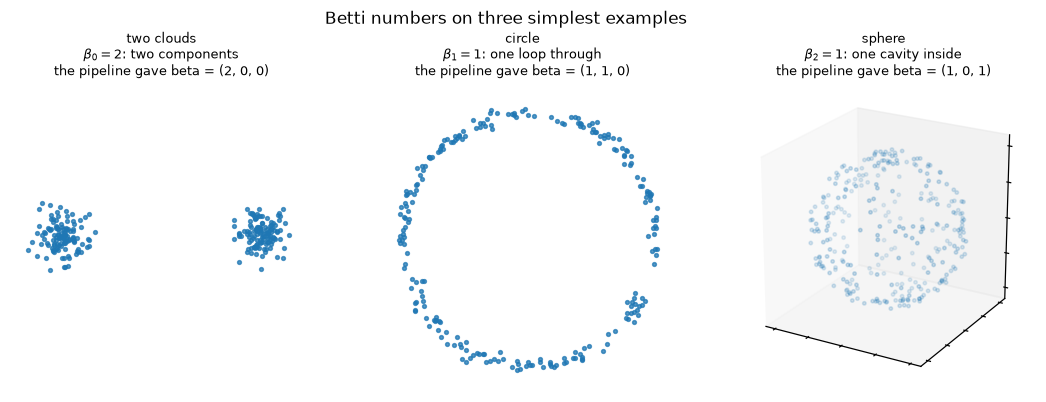

In [2]:
# Three simplest objects — one per Betti number.
demo_rng = rng_for(CONFIG.seed, "intro_demo")
two_blobs = np.vstack([demo_rng.normal(0, 0.28, size=(120, 2)) + [-2.2, 0],
                       demo_rng.normal(0, 0.28, size=(120, 2)) + [2.2, 0]])
demo_ring = build_static_cloud("circle", CONFIG, n_points=240, noise_sigma=0.03).points
demo_ball = build_static_cloud("sphere", CONFIG, n_points=300, noise_sigma=0.02).points

fig = plt.figure(figsize=(12, 4.2))
panels = [(two_blobs, "two clouds", r"$\beta_0 = 2$: two components", None),
          (demo_ring, "circle", r"$\beta_1 = 1$: one loop through", None),
          (demo_ball, "sphere", r"$\beta_2 = 1$: one cavity inside", (22, -60))]
for i, (pts, name, caption, view) in enumerate(panels, 1):
    if view is None:
        ax = fig.add_subplot(1, 3, i)
        ax.scatter(*pts.T, s=6, alpha=0.75)
        # A square window around the centre of the cloud: otherwise equal aspect makes the
        # panels incomparable in size — two flat blobs against a tall circle.
        centre, half = pts.mean(0), np.ptp(pts, axis=0).max() / 2 * 1.15
        ax.set_xlim(centre[0] - half, centre[0] + half)
        ax.set_ylim(centre[1] - half, centre[1] + half)
        ax.set_aspect("equal"); ax.axis("off")
    else:
        ax = fig.add_subplot(1, 3, i, projection="3d")
        ax.scatter(*pts.T, s=5, alpha=0.5)
        ax.set_box_aspect(np.ptp(pts, axis=0)); ax.view_init(*view)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([]); ax.grid(False)
    measured = significant_betti(pairwise_distances(pts), max_homology_dim=2,
                                 coeff_field=TOPOLOGY.coeff_field, criterion=TOPOLOGY.criterion,
                                 gap_noise_floor_ratio=TOPOLOGY.gap_noise_floor_ratio,
                                 gap_min_ratio=TOPOLOGY.gap_min_ratio)
    got = tuple(measured[k] for k in range(3))
    ax.set_title(f"{name}\n{caption}\nthe pipeline gave beta = {got}", fontsize=8.5)
fig.suptitle("Betti numbers on three simplest examples", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

This is already double checking in miniature: the expectation is formulated in advance
from the geometry, the number under the figure is obtained by computation, and they must agree.
The whole report that follows is the same thing, but on objects where agreeing is much harder.

## What was built: 38 datasets

A **dataset** is a directory on disk with two things: a data array (`points.npy`, `snapshots.npy`
or `series.npy`) and a file `ground_truth.json` recording which answer on these data is considered
correct. The directory name is a deterministic function of the generator, all its parameters and
the seed, so the same config always gives the same name and the same contents.

The table below has two columns that are easy to confuse:

- **`family`** is only **the layout on disk**: which subdirectory holds the dataset and which array
  file is expected in it.
- **`truth_kind`** is **the kind of truth**: what exactly is guaranteed and which fields must be
  present. `expected_betti` — Betti numbers; `betti_curve` — a Betti curve over time plus an event
  log; `partition` — a community partition and a schedule; `noise_level` — the noise mechanism and
  level; `none` — the truth is that there is no structure.

Up to family 3 the two coincided, and one field was enough. The dynamic SBM is the first object
where they diverged: on disk it is a dynamic graph, while its truth is a partition, with no barcode
in it at all. Requiring a Betti curve of it merely because snapshots lie on disk would encode the
false "dynamic graph ⇒ it has topological truth".

In [3]:
from tdadyn.core import replace_output_root
from tdadyn.synthetic.build import FAMILY_CHOICES, build_all
import tempfile, pathlib, time

with tempfile.TemporaryDirectory() as tmp:
    started = time.perf_counter()
    ENTRIES = build_all(replace_output_root(CONFIG, pathlib.Path(tmp)), FAMILY_CHOICES)
    elapsed = time.perf_counter() - started

rows = {}
for e in ENTRIES:
    rows.setdefault((e.family, e.generator), 0)
    rows[(e.family, e.generator)] += 1

print(f"{'family':<15}{'generator':<20}{'datasets':>9}")
print("-" * 44)
for (family, generator), n in sorted(rows.items()):
    print(f"{family:<15}{generator:<20}{n:>9}")
print("-" * 44)
print(f"{'TOTAL':<35}{len(ENTRIES):>9}")
print(f"\nfull build: {elapsed:.1f} s")

family         generator            datasets
--------------------------------------------
dynamic_graph  cycle_lifecycle             1
dynamic_graph  dynamic_sbm                 1
dynamic_graph  geometric_loop              1
noisy          missing_edges               8
noisy          point_jitter                4
noisy          spurious_edges              8
noisy          weight_jitter               4
null           erdos_renyi                 1
null           uniform_cloud               1
series         kuramoto                    1
series         roessler                    1
static_cloud   circle                      1
static_cloud   figure_eight                1
static_cloud   hopf_link                   1
static_cloud   klein_bottle                1
static_cloud   sphere                      1
static_cloud   torus                       1
static_cloud   two_circles                 1
--------------------------------------------
TOTAL                                     38

full buil

---
# S1–S2. Skeleton and the reference implementation

**S1** is infrastructure: truth dataclasses, deterministic directory names, writing and reading
datasets, derived random streams (one base seed yields an independent generator for each dataset
and each repeat). No generator uses the global `np.random.seed` — only an explicitly passed `rng`,
otherwise reproducibility would depend on the order of calls.

**S2** is the reference implementation of Betti numbers, and it was made **before the
generators**, because without it there is nothing to check them with. Below it is called "path B".

## Why a second implementation is needed

The main pipeline (path A) computes persistent homology with the `ripser` library — fast C++ code.
If the generators were checked only with it, then on a mismatch with the expectation it would be
unclear where the error is: in the generator or in how we call the library. So a second, fully
independent implementation — "path B" — is written next to it:

- it uses **no** persistence library;
- it computes Betti numbers directly from the definition: it builds **boundary matrices**
  $\partial_k$ (which $(k{-}1)$-faces enter the boundary of each $k$-simplex), takes their ranks
  over the field $\mathbb{Z}/2$ and applies
  $\beta_k = \dim\ker\partial_k - \operatorname{rank}\partial_{k+1}$;
- it is deliberately **slow**: over $\mathbb{Z}/2$ row addition is XOR, no division is needed at
  all, and the code stays short and readable. It applies only to small complexes (up to 30 nodes) —
  which is exactly why the dynamic scenarios are designed on 24 nodes.

The only purpose of path B is transparency. A test requires agreement of A, B and the table of
expectations from the document.

## Two layers, and why exactly two

**Layer 1, the homology engine** — takes an explicit list of simplices. The question "up to which
dimension to build" does not arise here at all: it computes what it is given.

**Layer 2, the flag complex builder** — takes a graph and turns it into a complex. A **flag
complex** (also clique complex): every clique of the graph, i.e. every set of vertices all
connected to each other, is declared a simplex. A triangle of three edges becomes a filled face,
$K_4$ a solid tetrahedron.

Two places where it is easy to go wrong here, both checked below:

1. **It must be built up to dimension $k_{\max}+1$.** $\beta_2$ needs 3-simplices:
   $\beta_2 = \dim\ker\partial_2 - \operatorname{rank}\partial_3$, and with a cut-off at
   dimension 2 the term $\operatorname{rank}\partial_3$ vanishes, and every closed
   two-dimensional surface is wrongly counted as a cavity.
2. **All cliques must be enumerated, not only maximal ones.** `networkx.find_cliques` returns only
   maximal ones and on $K_4$ would give one tetrahedron without edges and triangles.

In [4]:
def flag_faces(adjacency):
    complex_ = reference.flag_complex(adjacency, max_homology_dim=2, max_nodes=30)
    betti = reference.betti_numbers_of_graph(adjacency, max_homology_dim=2, max_nodes=30)
    return complex_.face_counts(), tuple(betti[k] for k in range(3))

def complete(n):
    a = np.ones((n, n)); np.fill_diagonal(a, 0.0); return a

def multipartite(sizes):
    labels = np.repeat(np.arange(len(sizes)), sizes)
    a = (labels[:, None] != labels[None, :]).astype(float)
    return a

cases = [("K3 (triangle)", complete(3), "filled: beta_1 = 0, while the cyclomatic number is 1"),
         ("K4", complete(4), "solid tetrahedron; a cut-off at dim 2 would give beta_2 = 1"),
         ("K_{2,2,2} (octahedron)", multipartite([2, 2, 2]), "a real cavity without 3-simplices")]

print(f"{'graph':<24}{'faces by dimension':<24}{'beta':<12}what it catches")
print("-" * 98)
for name, adjacency, why in cases:
    faces, betti = flag_faces(adjacency)
    print(f"{name:<24}{str(faces):<24}{str(betti):<12}{why}")

graph                   faces by dimension      beta        what it catches
--------------------------------------------------------------------------------------------------
K3 (triangle)           (3, 3, 1)               (1, 0, 0)   filled: beta_1 = 0, while the cyclomatic number is 1
K4                      (4, 6, 4, 1)            (1, 0, 0)   solid tetrahedron; a cut-off at dim 2 would give beta_2 = 1
K_{2,2,2} (octahedron)  (6, 12, 8)              (1, 0, 1)   a real cavity without 3-simplices


The face count of $K_4$ is (4, 6, 4, 1) — this is exactly the check that **all** cliques
are enumerated, not only maximal ones: `networkx.find_cliques` would return one tetrahedron
without edges and triangles, the boundary matrices would not match in dimensions, and $\beta_1$
would grow from 0 to 3.

### The objects themselves

From left to right: a triangle, whose flag complex fills the face; the complete graph on four
vertices, giving a solid tetrahedron; the octahedron, whose maximal clique is three, has no
3-simplices — and therefore keeps a real cavity.

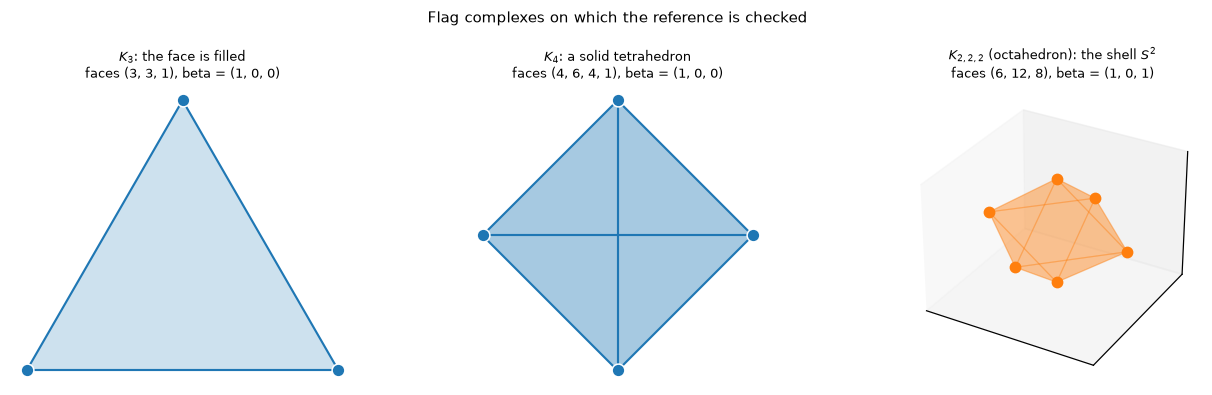

In [5]:
from matplotlib.patches import Polygon
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def triangles_of(adjacency):
    cx = reference.flag_complex(adjacency, max_homology_dim=2, max_nodes=30)
    return cx.simplices(2)

fig = plt.figure(figsize=(12, 3.6))

# K3 and K4 — flat diagrams with filled faces
for panel, (n, title) in enumerate([(3, "$K_3$: the face is filled"),
                                    (4, "$K_4$: a solid tetrahedron")], start=1):
    ax = fig.add_subplot(1, 3, panel)
    a = complete(n)
    ang = np.linspace(0, 2 * np.pi, n, endpoint=False) + np.pi / 2
    pos = np.c_[np.cos(ang), np.sin(ang)]
    for tri in triangles_of(a):
        ax.add_patch(Polygon(pos[list(tri)], closed=True, alpha=0.22,
                             facecolor="tab:blue", edgecolor="none"))
    for i in range(n):
        for j in range(i + 1, n):
            ax.plot(*pos[[i, j]].T, color="tab:blue", lw=1.4, zorder=2)
    ax.scatter(*pos.T, s=70, color="tab:blue", zorder=3, edgecolor="white")
    faces, betti = flag_faces(a)
    ax.set_title(f"{title}\nfaces {faces}, beta = {betti}", fontsize=8.5)
    ax.set_aspect("equal"); ax.axis("off")

# The octahedron — in 3D so that the cavity is visible
ax = fig.add_subplot(1, 3, 3, projection="3d")
oct_pos = np.array([[1, 0, 0], [-1, 0, 0], [0, 1, 0], [0, -1, 0], [0, 0, 1], [0, 0, -1]],
                   dtype=float)
oct_adj = multipartite([2, 2, 2])
tris = triangles_of(oct_adj)
ax.add_collection3d(Poly3DCollection([oct_pos[list(t)] for t in tris], alpha=0.25,
                                     facecolor="tab:orange", edgecolor="tab:orange", lw=0.8))
ax.scatter(*oct_pos.T, s=45, color="tab:orange", depthshade=False)
faces, betti = flag_faces(oct_adj)
ax.set_title(f"$K_{{2,2,2}}$ (octahedron): the shell $S^2$\nfaces {faces}, beta = {betti}",
             fontsize=8.5)
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_zlim(-1.2, 1.2)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.grid(False)

fig.suptitle("Flag complexes on which the reference is checked", fontsize=10)
fig.tight_layout(); plt.show()

The octahedron has 8 triangles and not a single 3-simplex — so its two-dimensional faces
form a closed surface that nothing fills, and $\beta_2 = 1$. $K_4$ also has 4 triangles, but there
is a tetrahedron that fills them, and the cavity disappears. Exactly this difference is caught by
the face count by dimension.

---
# S3–S4. Static clouds: family 1

Family 1 answers the question: **does the pipeline recover Betti numbers where they are known?**
The scheme is the same for all objects:

1. choose $N$ points on a manifold $M$ (as uniformly **by area** as possible, not by parameters —
   more on this below);
2. add Gaussian noise $\mathcal{N}(0,\sigma^2 I)$ in the ambient space;
3. compute the pairwise distance matrix, build the Vietoris–Rips filtration, get the persistence
   diagram;
4. compare the number of significant bars in each dimension with the table of expectations.

There are seven objects, chosen so that each breaks the pipeline in its own way:

| Object | $\beta$ | What makes it hard |
|---|---|---|
| Circle $S^1$ | (1,1,0) | basic test |
| Two circles | (2,2,0) | a check of $H_0$: the components must not stick together |
| Figure eight | (1,2,0) | point density drops near the self-intersection |
| Torus $T^2$ | (1,2,1) | $H_2$ lives at the scale of the small radius — easy to lose |
| Sphere $S^2$ | (1,0,1) | $\beta_1 = 0$: a check for **false** positives |
| Klein bottle | (1,2,1) over $\mathbb{Z}/2$ | the answer depends on the coefficient field |
| Hopf link | (2,2,0) | the components pass right next to each other but do not intersect |

Notation: the index of $S^n$ is the dimension of the **surface**, not of the ambient space. $S^1$
is a circle in the plane, $S^2$ a spherical shell in space, without the interior: hence
$\beta_2 = 1$.

The numbers in the table are obtained analytically and taken from `docs/method.md` §1.2. They are
an **input**, not a result: if a run does not reproduce them, the generator is fixed, not the
table.

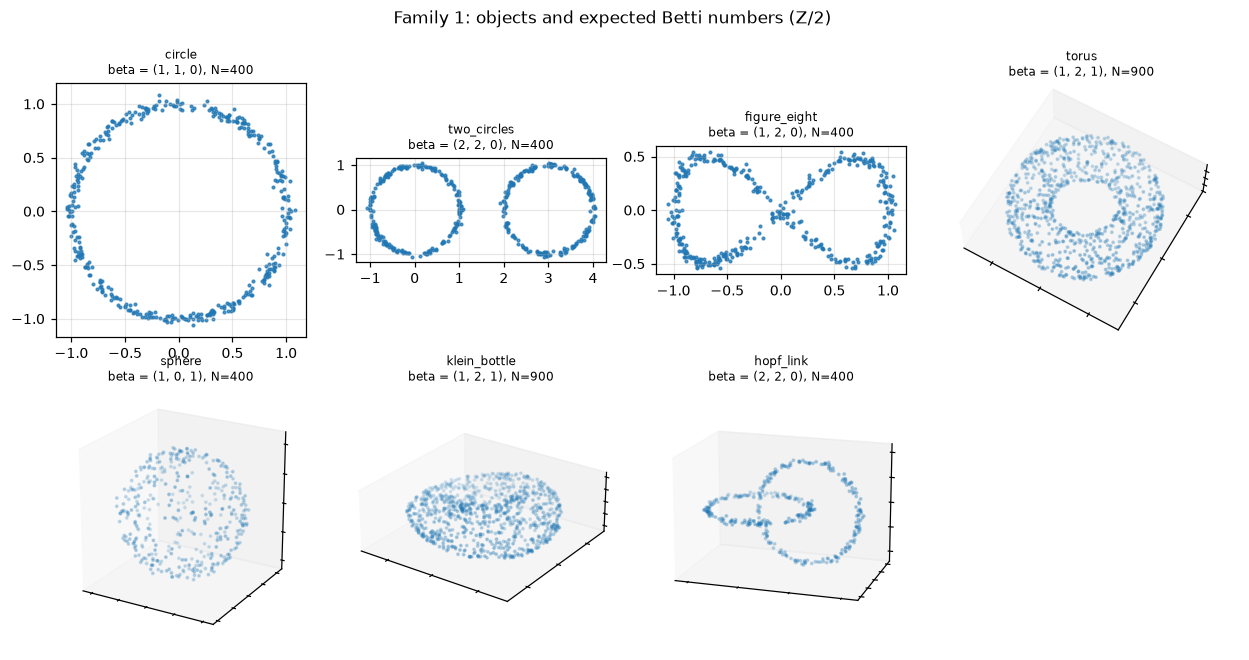

In [6]:
clouds = {name: build_static_cloud(name, CONFIG) for name in STATIC_GENERATORS}

# The view angle is chosen per object: the torus's hole is visible only from above, while the
# Hopf link needs a side view, otherwise the two circles overlap.
VIEW = {"torus": (62, -60), "sphere": (22, -60), "klein_bottle": (26, -55),
        "hopf_link": (16, -72)}

fig = plt.figure(figsize=(13.5, 6.6))
for i, (name, dataset) in enumerate(clouds.items(), 1):
    pts = dataset.points
    betti = dataset.ground_truth.expected_betti
    if pts.shape[1] == 2:
        ax = fig.add_subplot(2, 4, i)
        ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.75)
        ax.set_aspect("equal")
    else:
        ax = fig.add_subplot(2, 4, i, projection="3d")
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=2.5, alpha=0.55, depthshade=True)
        # Box proportions follow the actual extent: otherwise matplotlib stretches every axis
        # independently, and the torus (5.6 x 5.6 x 1.6) stops looking like a doughnut.
        ax.set_box_aspect(np.ptp(pts[:, :3], axis=0))
        elev, azim = VIEW[name]
        ax.view_init(elev=elev, azim=azim)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        ax.grid(False)
    ax.set_title(f"{name}\nbeta = {tuple(betti[k] for k in range(3))}, N={len(pts)}",
                 fontsize=8)
fig.suptitle("Family 1: objects and expected Betti numbers (Z/2)", fontsize=11)
fig.tight_layout(); plt.show()

The torus is shown from above — from other angles the hole in the middle does not read —
and the box proportions are set from the extent of the cloud: by default matplotlib scales every
axis independently, and a $5.6 \times 5.6 \times 1.6$ torus looks like a flattened pancake. The
Hopf link, conversely, is shown from the side — from above the two circles overlap.

### What persistence sees: the Vietoris–Rips filtration

The cloud itself is not given to the algorithm — a **nested family of complexes** is built from it
by growing scale $\varepsilon$.

The points below are placed **uniformly**, as in the closed state of `geometric_loop`
($\delta = 2\pi/n$ gives a step of exactly $2\pi/n$). This is a didactic choice: the family-1
generators sample $\theta$ randomly, and on fifteen-odd points the gaps between neighbours differ
by a factor of hundreds — the picture would come out ragged and would say nothing about the
mechanism of the filtration. It is precisely because of random sampling that recovering Betti
numbers on the real datasets takes hundreds of points, not fifteen.

arc step 0.393, neighbour chord 0.390


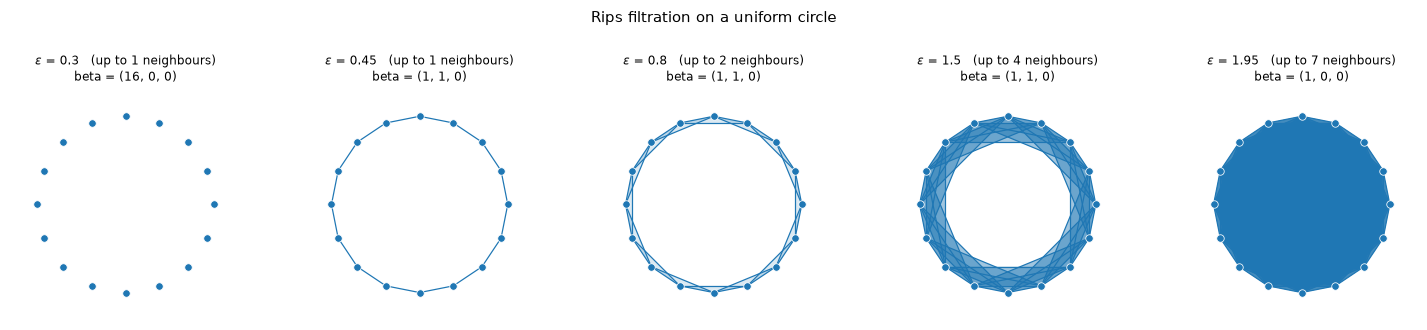

In [7]:
n_demo = 16
a_demo = np.arange(n_demo) * 2 * np.pi / n_demo
demo = np.c_[np.cos(a_demo), np.sin(a_demo)]
demo_d = pairwise_distances(demo)
print(f"arc step {2*np.pi/n_demo:.3f}, neighbour chord {2*np.sin(np.pi/n_demo):.3f}")

fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.0))
for ax, eps in zip(axes, [0.30, 0.45, 0.80, 1.50, 1.95]):
    adj = adjacency_from_snapshot(demo_d, edge_rule="distance_within", edge_threshold=eps)
    for tri in triangles_of(adj):
        ax.add_patch(Polygon(demo[list(tri)], closed=True, alpha=0.16,
                             facecolor="tab:blue", edgecolor="none"))
    iu = np.triu_indices(n_demo, 1)
    for i, j in zip(iu[0][adj[iu] > 0], iu[1][adj[iu] > 0]):
        ax.plot(*demo[[i, j]].T, color="tab:blue", lw=0.8, zorder=2)
    ax.scatter(*demo.T, s=24, color="tab:blue", zorder=3, edgecolor="white", lw=0.5)
    b = reference.betti_numbers_of_graph(adj, max_homology_dim=2, max_nodes=30)
    neighbours = int(round(np.arcsin(min(eps, 2) / 2) / (np.pi / n_demo)))
    ax.set_title(f"$\\varepsilon$ = {eps}   (up to {neighbours} neighbours)\n"
                 f"beta = {(b[0], b[1], b[2])}", fontsize=8)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
fig.suptitle("Rips filtration on a uniform circle", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

From left to right: isolated vertices, the birth of a loop, the loop living on as edges and
triangles grow denser, and finally $\beta_1$ disappears.

**The last panel is not "the loop got filled".** By Adamaszek–Adams the Rips complex of a circle
is, as the relative scale grows, successively equivalent to $S^1, S^3, S^5, \dots$ — it does not
contract. At $\varepsilon = 1.95$ every vertex is connected to seven neighbours on each side, the
complex has left the $S^1$ regime, and the class born lives in a dimension above
`max_homology_dim = 2`, i.e. it is **not visible**. The death of $\beta_1$ for no visible reason
here is exactly the known artefact that `method.md` §5 lists among "not bugs": it does not need
fixing, it is enough to limit the range of significance.

The same on a full cloud, as a barcode: each bar is a class that lives from its birth to its
death. The long bar in $H_1$ is the loop of the circle; the short ones are sampling noise.

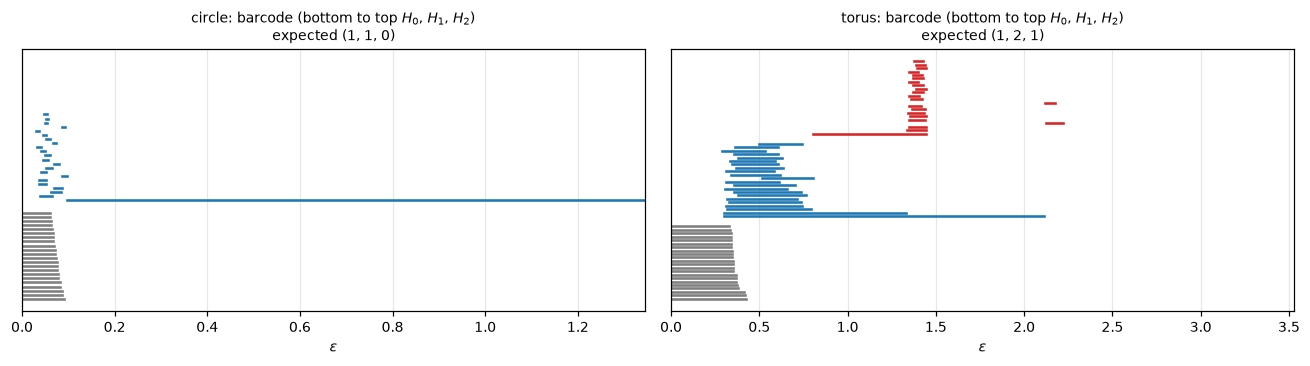

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, name in zip(axes, ("circle", "torus")):
    pts = clouds[name].points
    dgms = persistence_diagrams(pairwise_distances(pts), max_homology_dim=2,
                                coeff_field=TOPOLOGY.coeff_field)
    diam = pairwise_distances(pts).max()
    colours = {0: "tab:gray", 1: "tab:blue", 2: "tab:red"}
    y = 0
    for dim in (0, 1, 2):
        d = dgms[dim]
        d = d[np.isfinite(d[:, 1])]
        order = np.argsort(-(d[:, 1] - d[:, 0]))[:22]
        for b, dth in d[order]:
            ax.plot([b, dth], [y, y], lw=1.7, color=colours[dim])
            y += 1
        y += 2
    expected = clouds[name].ground_truth.expected_betti
    ax.set_title(f"{name}: barcode (bottom to top $H_0$, $H_1$, $H_2$)\n"
                 f"expected {tuple(expected[k] for k in range(3))}", fontsize=9)
    ax.set_xlabel(r"$\varepsilon$"); ax.set_yticks([]); ax.set_xlim(0, diam * 0.62)
fig.tight_layout(); plt.show()

The Klein bottle is embedded in $\mathbb{R}^4$ and shown as a projection onto the first
three coordinates. In the picture it **looks like a torus** — and this is not a defect of the
figure: the projection loses exactly the gluing that tells them apart. In $\mathbb{R}^3$ there is
only an immersion with self-intersection, which would spoil the ground truth, so a
four-dimensional embedding is used. What can tell these two objects apart here is not the eye but
the coefficient field: over $\mathbb{Z}/2$ the Klein bottle gives $(1,2,1)$, over $\mathbb{Z}/3$
$(1,1,0)$, while the torus's answer does not depend on the field.

### Sampling uniformity: where a naive implementation looks plausible

The torus is parametrised by two angles, $\theta$ along the large circle and $\varphi$ along the
small one. It is tempting to take both uniformly from $U(0, 2\pi)$ — and that is **wrong**: the
surface area element is proportional to $(R + r\cos\varphi)$, i.e. the outer rim of the doughnut
is wider than the inner one. Uniform sampling of the angles puts the same number of points on both,
and the inner rim ends up oversampled several times.

The cure is **rejection sampling**: a proposed $\varphi$ is accepted with probability proportional
to the area element, otherwise it is redrawn. The same is done for the Klein bottle for the same
reason; for the sphere the role of such a technique is played by Muller's method — take
$g \sim \mathcal{N}(0, I_3)$ and normalise $g/\lVert g\rVert$, whereas naive sampling of
spherical angles clusters points at the poles.

Why it matters: non-uniformity distorts the filtration and **can eat the bar** $\beta_2$. Yet the
cloud looks perfectly normal, and the error shows up nowhere except in the final number. So
uniformity has its own test — a Kolmogorov–Smirnov test against the theoretical density.

Below: on the left a histogram of the actually drawn $\varphi$ against the curve
$\propto (R + r\cos\varphi)$; on the right the distribution of the $z$ coordinate on the sphere,
which for uniform sampling must be **flat** (a property of the sphere known as Archimedes'
theorem).

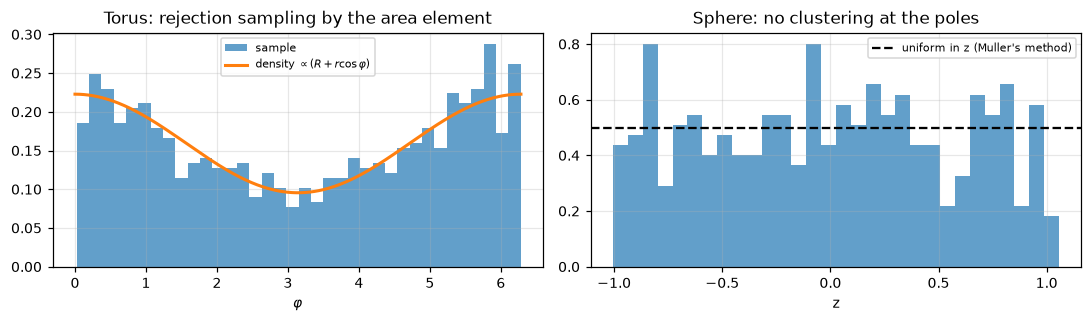

In [9]:
phi = np.linspace(0, 2 * np.pi, 400)
R, r = CONFIG.static_clouds.torus.R, CONFIG.static_clouds.torus.r
density = (R + r * np.cos(phi)) / (2 * np.pi * R)

torus = clouds["torus"].points
angle = np.arctan2(torus[:, 2], np.hypot(torus[:, 0], torus[:, 1]) - R) % (2 * np.pi)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(angle, bins=36, density=True, alpha=0.7, label="sample")
ax[0].plot(phi, density, lw=2, label=r"density $\propto (R + r\cos\varphi)$")
ax[0].set_title("Torus: rejection sampling by the area element"); ax[0].legend(fontsize=7)
ax[0].set_xlabel(r"$\varphi$")

sphere = clouds["sphere"].points
ax[1].hist(sphere[:, 2], bins=30, density=True, alpha=0.7)
ax[1].axhline(0.5, color="k", lw=1.5, ls="--", label="uniform in z (Muller's method)")
ax[1].set_title("Sphere: no clustering at the poles"); ax[1].legend(fontsize=7)
ax[1].set_xlabel("z")
fig.tight_layout(); plt.show()

## The main result of S4: the significance criterion had to be replaced

### What the problem is

The barcode of a noisy cloud contains **hundreds** of bars: real features mixed with sampling
noise. To get Betti numbers from it, a rule is needed that separates one from the other. This rule
is not an implementation detail but the place where the answer finally takes shape, and an error
in it looks like an error of the whole pipeline.

Originally the project recorded a natural rule: a bar is significant if its persistence is at
least `significance_ratio` × $\mathrm{diam}(X)$, i.e. a given fraction of the cloud's diameter. A
run showed that it is **unfit** — and this was established by measurement, not by argument. It errs
**in both directions**:

- on **anisotropic** objects (torus, Klein bottle) it loses $H_2$. For the torus $R{=}2.0$,
  $r{=}0.8$ the cavity lives at the scale of the small radius $r$, while the threshold is
  normalised by the diameter $2(R+r)$: at 400 points the bar is 0.257 against a threshold of 0.851
  — it fails, although the feature is there;
- on **compact** objects (sphere) it gives extra loops in $H_1$: the diameter is small (2.12), the
  threshold with it (0.32), and noise bars of length 0.260, 0.256, 0.254 sit right against it. On
  some seeds the result is $(1,1,1)$ instead of $(1,0,1)$ — a loop where there is none.

And the main point: a noise bar of the sphere is 0.123 of the diameter, while the **useful** $H_2$
bar of the torus at 400 points is 0.045 of the diameter, i.e. three times **smaller** than the
noise one. The signal and noise ranges in fractions of the diameter overlap, so no common threshold
normalised by the diameter will give the right answer on both objects at once. This is not a matter
of tuning a constant.

### What separates them reliably

A gap in the spectrum. If the persistences within one dimension are sorted in decreasing order, a
real feature is followed by a **sharp drop**, while noise goes in an even staircase. In the figure
below: bars are persistences in decreasing order, the labels between them the ratio of neighbours,
the red line the noise floor.

What to look at is where **the largest ratio** stands. The torus here at 900 points, the sphere at
400 — the working sizes from the config:

- torus, $H_1$: 1.813 1.034 0.477 0.431, ratios 1.75x **2.17x** 1.11x — the gap at position 2,
  i.e. $\beta_1 = 2$;
- torus, $H_2$: 0.641 0.107 0.095 0.095, ratios **6.01x** 1.12x 1.00x — position 1,
  $\beta_2 = 1$;
- sphere, $H_1$: 0.260 0.256 0.254 0.206, ratios 1.02x 1.01x 1.24x — all below
  `gap_min_ratio` = 1.55, there is no pronounced gap at all, and the rule honestly gives zero.

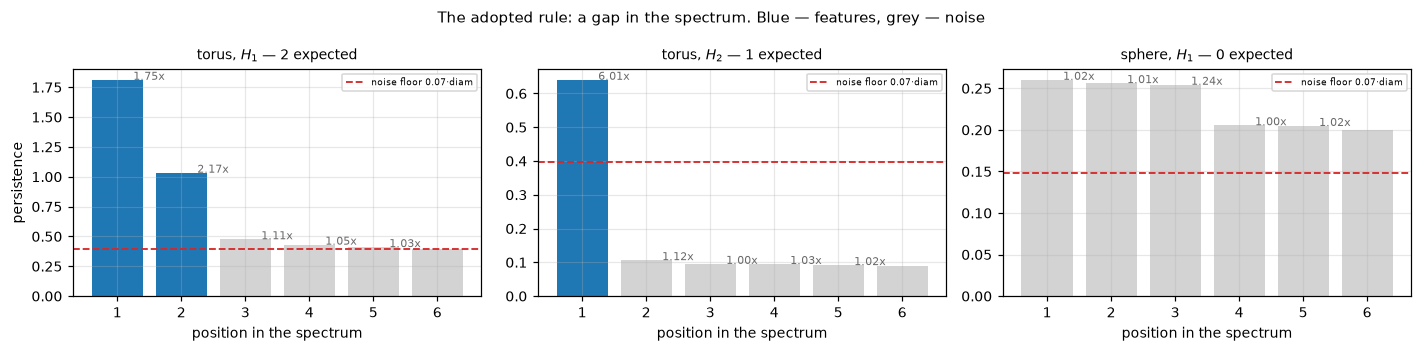

In [10]:
def spectrum(points, dim, n=6):
    d = pairwise_distances(points)
    dgm = persistence_diagrams(d, max_homology_dim=2, coeff_field=TOPOLOGY.coeff_field)[dim]
    finite = dgm[np.isfinite(dgm[:, 1])]
    pers = np.sort(finite[:, 1] - finite[:, 0])[::-1]
    return pers[:n], d.max()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
panels = [("torus", 1, 2, "torus, $H_1$ — 2 expected"),
          ("torus", 2, 1, "torus, $H_2$ — 1 expected"),
          ("sphere", 1, 0, "sphere, $H_1$ — 0 expected")]
for ax, (name, dim, expected, title) in zip(axes, panels):
    pers, diam = spectrum(clouds[name].points, dim)
    floor = TOPOLOGY.gap_noise_floor_ratio * diam
    ax.bar(range(1, len(pers) + 1), pers, color=["tab:blue"] * expected +
           ["lightgray"] * (len(pers) - expected))
    ax.axhline(floor, color="tab:red", ls="--", lw=1.2,
               label=f"noise floor {TOPOLOGY.gap_noise_floor_ratio}·diam")
    for i in range(len(pers) - 1):
        if pers[i + 1] > 0:
            ax.text(i + 1.5, pers[i], f"{pers[i] / pers[i + 1]:.2f}x", fontsize=7,
                    ha="center", color="dimgray")
    ax.set_title(title, fontsize=9); ax.set_xlabel("position in the spectrum"); ax.legend(fontsize=6)
axes[0].set_ylabel("persistence")
fig.suptitle("The adopted rule: a gap in the spectrum. Blue — features, grey — noise", fontsize=10)
fig.tight_layout(); plt.show()

**The adopted rule is a gap in the spectrum with a step into the dust.** Within each
dimension: persistences are sorted, bars below the noise floor are set aside, the largest ratio of
neighbouring values is sought **including the step from the last survivor to the first set-aside
one**, and $\beta_k$ equals the position of that gap.

The step into the dust was introduced for the case $\beta_k = 0$: without it the rule always
returns at least one feature. It also fixes two disjoint circles, where two nearly equal bars remain
above the floor (1.473 and 1.453, ratio 1.01) and there is no gap between them.

**Calibration result:** the rule is correct on all 54 combinations (9 cases × 3 seeds × 2 noise
levels). The parameters are taken from the **centre** of the zero-miss region, not from its edge:
zero holds at floor 0.05–0.10 and gap 1.45–1.62; 0.07 and 1.55 are adopted. The old rule gives 9
misses on the same table.

*These four numbers are a quotation from `docs/method.md` §1.2a, not the output of a cell: the full
calibration table is computed by a separate harness (`calibration.py`) and takes tens of minutes.
Everything else in this section is computed here.*

In [11]:
print("Check: the criterion against the table of expectations (path A, clean clouds)\n")
print(f"{'object':<16}{'expected':<12}{'measured':<12}")
print("-" * 40)
for name, dataset in clouds.items():
    expected = dataset.ground_truth.expected_betti
    measured = significant_betti(
        pairwise_distances(dataset.points), max_homology_dim=2,
        coeff_field=TOPOLOGY.coeff_field, criterion=TOPOLOGY.criterion,
        gap_noise_floor_ratio=TOPOLOGY.gap_noise_floor_ratio,
        gap_min_ratio=TOPOLOGY.gap_min_ratio)
    exp, got = tuple(expected[k] for k in range(3)), tuple(measured[k] for k in range(3))
    print(f"{name:<16}{str(exp):<12}{str(got):<12}{'' if exp == got else '  <-- MISMATCH'}")

Check: the criterion against the table of expectations (path A, clean clouds)

object          expected    measured    
----------------------------------------


circle          (1, 1, 0)   (1, 1, 0)   


two_circles     (2, 2, 0)   (2, 2, 0)   


figure_eight    (1, 2, 0)   (1, 2, 0)   


torus           (1, 2, 1)   (1, 2, 1)   


sphere          (1, 0, 1)   (1, 0, 1)   


klein_bottle    (1, 2, 1)   (1, 2, 1)   


hopf_link       (2, 2, 0)   (2, 2, 0)   


**The Hopf link gives $\beta_0 = 2$, and that is not an error.** Two linked circles have
exactly the same homology as two unlinked ones: linking is a property of the embedding, not of the
homotopy type. The dataset serves as a geometric stress test (the pipeline must not prematurely glue
together components passing close to each other), not as a source of a separate topological
signature.

---
# S5. Cloud → weighted network

### Why this step

So far the input was **points**. But the data for which all this is undertaken — functional brain
connectomes — arrive not as a point cloud but as a **weighted network**: a connectivity matrix
between regions. For the validation harness to work on the same type of object, a transition
"cloud → network" is needed, and one that preserves the known topology of the cloud.

There are two ways, and both are needed:

- **Gaussian similarity kernel:** $w_{ij} = \exp(-d_{ij}^2 / 2\sigma^2)$. Gives a **fully
  connected** weighted network — exactly the type of object a connectome is.
- **Geodesics over a $k$-NN graph:** connect each point to its $k$ nearest, and take as distance
  the length of the shortest path in that graph. This is the Isomap construction, and it
  approximates **the intrinsic metric of the manifold**: on a curved surface a path "along the
  surface" reflects its structure more faithfully than a straight line through the ambient space.

Back into distances (the filtration works with distances, not similarities) goes a monotonically
decreasing function: $d = \sqrt{-2\sigma^2\log w}$ or $d = 1-w$. A non-monotone transform would
permute the order in which edges enter and silently change the answer.

### Two knobs, each with a working window

**$k$ works in a window, not "the larger the better".** From below the graph falls apart into
components, and some geodesic distances become infinite. From above **short-circuiting** sets in —
a known failure of Isomap: chord edges cutting across the holes appear, and the intrinsic metric
degenerates into the ambient one, i.e. the whole point of the construction is lost.

A cheap guard that needs no persistent computations is the ratio of the geodesic diameter to the
Euclidean one, $\mathrm{diam}_{geo}/\mathrm{diam}_{euclid}$: approaching one means the graph has
become practically complete and the metric has degenerated.

**The kernel width $\sigma$** is the second knob, and it turned out to be the main source of errors
at this step. The left panel below shows the window in $k$, the right one the distribution of
weights at two width values.

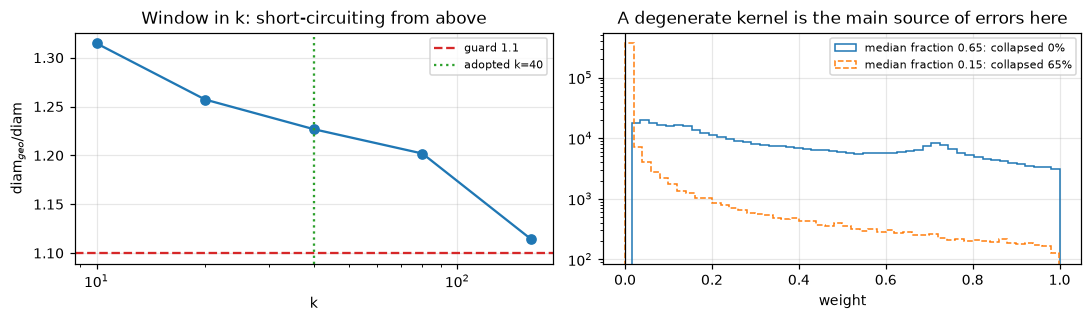

In [12]:
from tdadyn.synthetic.network import (collapsed_weight_fraction, gaussian_kernel,
                                      geodesic_diameter_ratio, kernel_width,
                                      knn_geodesic_distances, knn_graph)

net = CONFIG.network_from_cloud
torus_d = pairwise_distances(clouds["torus"].points)
ks = [10, 20, 40, 80, 160]
ratios = []
for k in ks:
    geo = knn_geodesic_distances(torus_d, k=k, symmetrize=net.knn_symmetrize)
    ratios.append(geodesic_diameter_ratio(geo, torus_d))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ks, ratios, "o-")
ax[0].axhline(net.min_geodesic_diameter_ratio, color="tab:red", ls="--",
              label=f"guard {net.min_geodesic_diameter_ratio}")
ax[0].axvline(net.knn_k, color="tab:green", ls=":", label=f"adopted k={net.knn_k}")
ax[0].set_xscale("log"); ax[0].set_xlabel("k"); ax[0].set_ylabel(r"diam$_{geo}$/diam")
ax[0].set_title("Window in k: short-circuiting from above"); ax[0].legend(fontsize=7)

for fraction, style in ((net.kernel_sigma_median_fraction, "-"), (0.15, "--")):
    sigma = kernel_width(torus_d, median_fraction=fraction)
    w = gaussian_kernel(torus_d, sigma=sigma)
    collapsed = collapsed_weight_fraction(w)
    ax[1].hist(w[np.triu_indices_from(w, 1)], bins=50, histtype="step", ls=style,
               label=f"median fraction {fraction}: collapsed {collapsed:.0%}")
ax[1].axvline(1e-6, color="k", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlabel("weight"); ax[1].legend(fontsize=7)
ax[1].set_title("A degenerate kernel is the main source of errors here")
fig.tight_layout(); plt.show()

The kernel width is set **as a fraction of the median pairwise distance**, not as an
absolute number: family-1 objects differ in scale, and an absolute value suiting one collapses
another. Measured: at $\sigma = 0.5$ and a torus diameter of 5.71 the fraction of weights below
$10^{-6}$ is 60%, and the transform $1-w$ works with already destroyed data.

### What the network itself looks like

One and the same cloud — a circle — in three forms: the edges of the Gaussian kernel with
transparency by weight, the same network as a matrix, and the sparse $k$-NN graph over which the
geodesics are computed.

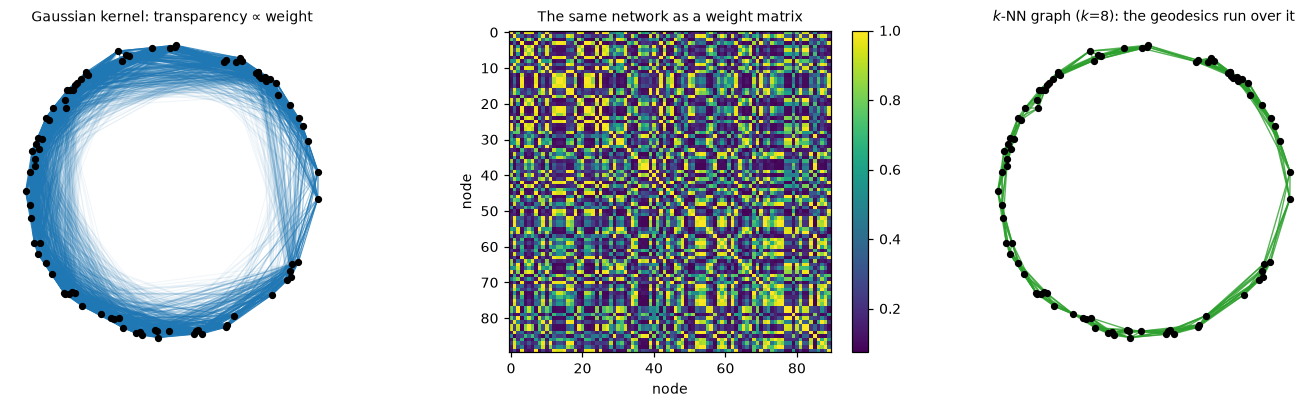

In [13]:
ring = build_static_cloud("circle", CONFIG, n_points=90, noise_sigma=0.02).points
ring_d = pairwise_distances(ring)
sigma = kernel_width(ring_d, median_fraction=net.kernel_sigma_median_fraction)
W = gaussian_kernel(ring_d, sigma=sigma)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.7))

iu = np.triu_indices_from(W, 1)
strong = W[iu] > 0.25
for i, j, w in zip(iu[0][strong], iu[1][strong], W[iu][strong]):
    ax[0].plot(*ring[[i, j]].T, color="tab:blue", lw=0.7, alpha=float(w) ** 2)
ax[0].scatter(*ring.T, s=14, color="k", zorder=3)
ax[0].set_title("Gaussian kernel: transparency ∝ weight", fontsize=9)
ax[0].set_aspect("equal"); ax[0].axis("off")

im = ax[1].imshow(W, cmap="viridis")
ax[1].set_title("The same network as a weight matrix", fontsize=9)
ax[1].set_xlabel("node"); ax[1].set_ylabel("node"); ax[1].grid(False)
fig.colorbar(im, ax=ax[1], fraction=0.046)

knn = knn_graph(ring_d, k=8, symmetrize=net.knn_symmetrize)
ku = np.triu_indices_from(knn, 1)
for i, j in zip(ku[0][knn[ku] > 0], ku[1][knn[ku] > 0]):
    ax[2].plot(*ring[[i, j]].T, color="tab:green", lw=0.9, alpha=0.8)
ax[2].scatter(*ring.T, s=14, color="k", zorder=3)
ax[2].set_title("$k$-NN graph ($k$=8): the geodesics run over it", fontsize=9)
ax[2].set_aspect("equal"); ax[2].axis("off")
fig.tight_layout(); plt.show()

The Gaussian kernel gives a **fully connected** weighted network — the same type of object
as the functional connectome of Task 3. The $k$-NN graph is sparse, but the matrix of shortest
paths over it is dense again, so it is not a means of controlling complexity: its value is that the
intrinsic metric on a curved manifold reflects the structure more faithfully than the ambient
one.

---
# S6. Dynamic graphs with scheduled events

### What is new here

So far the object was static: one cloud, one answer. Family 2 introduces **time**: a sequence of
graph snapshots $G_0, \dots, G_{59}$ in which topological features are born and die at moments
scheduled in advance.

This is the main dataset for **Task 2** — zigzag persistence algorithms. "Zigzag" here means that
neighbouring snapshots are linked through their union,
$K_i \hookrightarrow K_i \cup K_{i+1} \hookleftarrow K_{i+1}$, i.e. the inclusions alternate in
direction: the graph not only grows but also loses edges. From such a sequence the algorithm must
say which class was born when and when it died.

### How events translate: words and homology are not the same

The place where mistakes are most frequent. Intuitive wordings in the language of graphs and events
in the language of homology do not coincide:

| Event on the graph | Homological event | $\beta$ |
|---|---|---|
| Components merge | death of an $H_0$ class | $\beta_0 - 1$ |
| A component splits | birth of an $H_0$ class | $\beta_0 + 1$ |
| A path closes into a cycle | birth of an $H_1$ class | $\beta_1 + 1$ |
| A chord is added to a cycle | **birth** of a new $H_1$ class | $\beta_1 + 1$ |
| An edge of a cycle is removed | death of an $H_1$ class | $\beta_1 - 1$ |

Note the row about the chord: in the language of graphs it is a "split" of one cycle into two, in
the language of homology a **birth**, not a split. A barcode has no operation of splitting a class
at all; there are only births and deaths. So in JSON the `type` field takes **only** `birth` or
`death`, and the intuitive wording goes into a separate field `narrative`.

### The `cycle_lifecycle` scenario

24 nodes, 60 snapshots, five scheduled events:

1. the path $0-1-\dots-23$, no cycles ($\beta_1 = 0$);
2. **snapshot 12**: closing by the edge $(23,0)$ → birth of a class in $H_1$;
3. **snapshot 27**: the chord $(0,12)$ splits the 24-cycle in two → birth of a second class;
4. **snapshot 41**: removing the edge $(6,7)$ → death of a class in $H_1$;
5. **snapshot 48**: removing $(3,4)$ detaches a component → birth of a class in $H_0$;
6. **snapshot 55**: restoring $(3,4)$ → merge, death of a class in $H_0$.

No triangles arise in the scenario on any snapshot — otherwise the flag complex would fill a cycle
and the event that happened would differ from the one recorded in the log.

**Index convention.** The record `snapshot: k` means that $G_k$ **already contains** the change and
$G_{k-1}$ does not yet; the jump of the curve falls on the transition $k-1 \to k$. The alternative
reading shifts the whole log by one, invisible inside this family and surfacing only in Task 2 —
where it would look like a systematic error of the localisation algorithm.

### The truth here is twofold

`events` is the scheduler's intent, recorded during construction. `betti_curve` is computed by the
reference implementation (path B) from **the snapshots written to disk**, not from the scheduler's
internal state: otherwise the curve would describe the intent rather than what landed on disk. A
test requires them to match exactly — multisets of "position, direction" pairs are compared, not
counts, otherwise a shift of all events by one would go unnoticed.

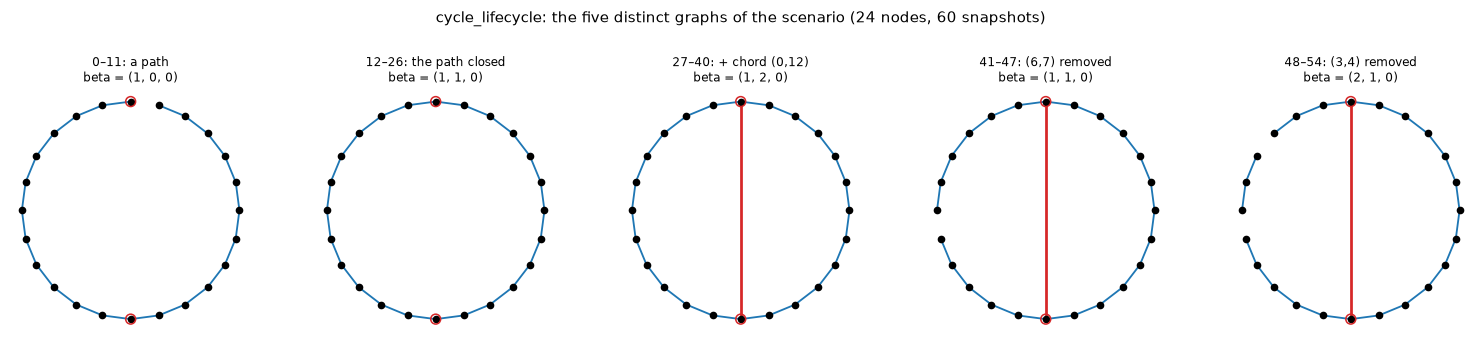

In [14]:
lifecycle = build_dynamic_graph("cycle_lifecycle", CONFIG)
gt = lifecycle.ground_truth
curve, events = gt.betti_curve, gt.events

# Five distinct graphs over 60 snapshots: the whole scenario fits in one row.
n_nodes = lifecycle.snapshots.shape[1]
ang = np.linspace(0, 2 * np.pi, n_nodes, endpoint=False) + np.pi / 2
ring_pos = np.c_[np.cos(ang), np.sin(ang)]
phases = [(0, "0–11: a path"), (12, "12–26: the path closed"), (27, "27–40: + chord (0,12)"),
          (41, "41–47: (6,7) removed"), (48, "48–54: (3,4) removed")]

fig, axes = plt.subplots(1, 5, figsize=(14, 3.1))
for ax, (t, title) in zip(axes, phases):
    adj = adjacency_from_snapshot(lifecycle.snapshots[t], edge_rule=gt.edge_rule,
                                  edge_threshold=gt.edge_threshold)
    iu = np.triu_indices(n_nodes, 1)
    for i, j in zip(iu[0][adj[iu] > 0], iu[1][adj[iu] > 0]):
        chord = abs(i - j) not in (1, n_nodes - 1)
        ax.plot(*ring_pos[[i, j]].T, color="tab:red" if chord else "tab:blue",
                lw=1.8 if chord else 1.2, zorder=2)
    ax.scatter(*ring_pos.T, s=16, color="k", zorder=3)
    for node in (0, 12):
        ax.scatter(*ring_pos[node], s=42, facecolor="none", edgecolor="tab:red", zorder=4)
    b = curve[0][t], curve[1][t], curve[2][t]
    ax.set_title(f"{title}\nbeta = {b}", fontsize=8)
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("cycle_lifecycle: the five distinct graphs of the scenario (24 nodes, 60 snapshots)",
             fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

The chord $(0,12)$ is shown in red: it splits the 24-cycle into two cycles of length 13,
both at least three edges long — otherwise the flag complex would fill a triangle and the second
birth in $H_1$ would not happen. There are no triangles in the scenario on any snapshot, by
construction.

Snapshots 55–59 coincide with 41–47 **byte for byte**: restoring the edge returns the graph exactly
to its former state. This is intentional — the repetition checks that the pipeline does not collapse
states by graph identity and honestly reports the separate birth and death of $H_0$.

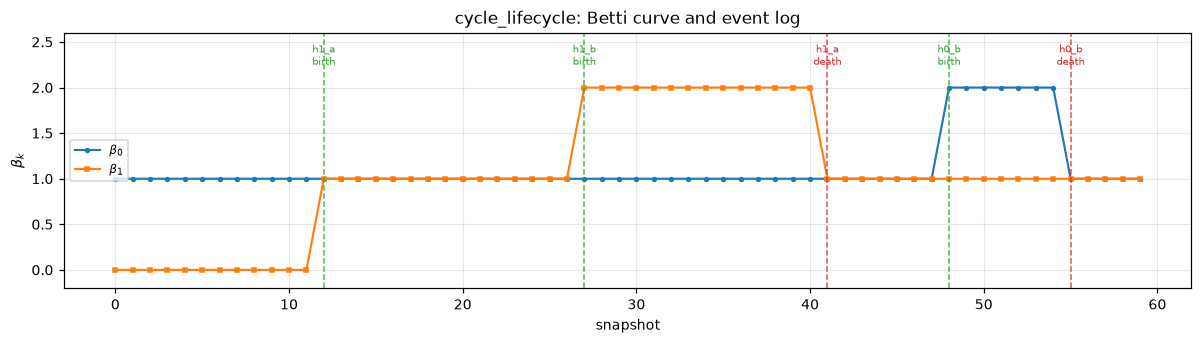

 snapshot  dim    type   feature   description
--------------------------------------------------------------------------------
       12    1   birth      h1_a   the path closes into a cycle
       27    1   birth      h1_b   a chord splits the cycle in two
       41    1   death      h1_a   an edge of the arc cut off by the chord is removed
       48    0   birth      h0_b   a component detaches from the dangling path
       55    0   death      h0_b   the components merge back


In [15]:
# The narratives are recorded truth and stay in the language they were generated in; the
# English gloss below is for the reader and is not part of any dataset.
GLOSS = {"h1_a": {"birth": "the path closes into a cycle",
                  "death": "an edge of the arc cut off by the chord is removed"},
         "h1_b": {"birth": "a chord splits the cycle in two"},
         "h0_b": {"birth": "a component detaches from the dangling path",
                  "death": "the components merge back"}}

fig, ax = plt.subplots(figsize=(11, 3.2))
for dim, style in ((0, "-o"), (1, "-s")):
    ax.plot(curve[dim], style, ms=2.5, lw=1.4, label=f"$\\beta_{dim}$")
for e in events:
    ax.axvline(e.snapshot, color="tab:red" if e.type == "death" else "tab:green",
               ls="--", lw=1, alpha=0.8)
    ax.text(e.snapshot, 2.25, f"{e.feature_id}\n{e.type}", fontsize=6.5, ha="center",
            color="tab:red" if e.type == "death" else "tab:green")
ax.set_xlabel("snapshot"); ax.set_ylabel(r"$\beta_k$"); ax.set_ylim(-0.2, 2.6)
ax.set_title("cycle_lifecycle: Betti curve and event log")
ax.legend(fontsize=8, loc="center left"); fig.tight_layout(); plt.show()

print(f"{'snapshot':>9}{'dim':>5}{'type':>8}{'feature':>10}   description")
print("-" * 80)
for e in events:
    gloss = GLOSS.get(e.feature_id, {}).get(e.type, e.narrative)
    print(f"{e.snapshot:>9}{e.dim:>5}{e.type:>8}{e.feature_id:>10}   {gloss}")

### Two decisions that look arbitrary and are not

**The death at snapshot 41 is paired with the birth at 12 (`h1_a`), not at 27.** The decomposition
of a zigzag module into interval modules is unique (Krull–Schmidt for a quiver of type $A_n$), so
the pairing is determined and cannot be assigned. Over $\mathbb{Z}/2$: $c_1$ is the cycle through
the chord along the arc $0..12$, $c_2$ along the arc $12..23..0$, $c = c_1 + c_2$ the original
24-cycle. The images of the inclusions are different lines, and the intervals come out as
$[12, 40]$ and $[27, \infty)$.

The intuition "the chord split the cycle in two, break one and the younger dies" is **wrong** here.

**The cost of the error:** a log with inverted pairing breaks no test inside family 2 — the Betti
curve does not see pairing. It would surface in Task 2 as a systematically "wrong" pair, and
debugging would go into the algorithm rather than the log.

In [16]:
theta = lifecycle.snapshots[40]
broken = lifecycle.snapshots[41]
theta_graph = adjacency_from_snapshot(theta, edge_rule=gt.edge_rule,
                                      edge_threshold=gt.edge_threshold)
cx = reference.flag_complex(theta_graph, max_homology_dim=2, max_nodes=30)
edges = cx.simplices(1)
position = {e: i for i, e in enumerate(edges)}
boundary = reference.boundary_matrix(cx, 1).astype(np.int64)

def chain(pairs):
    v = np.zeros(len(edges), dtype=np.int64)
    for p in pairs:
        v[position[tuple(sorted(p))]] = 1
    return v

cycle24 = chain([(i, i + 1) for i in range(23)] + [(23, 0)])
c2 = chain([(i, i + 1) for i in range(12, 23)] + [(23, 0), (0, 12)])
removed = position[(6, 7)]
broken_graph = adjacency_from_snapshot(broken, edge_rule=gt.edge_rule,
                                       edge_threshold=gt.edge_threshold)
betti41 = reference.betti_numbers_of_graph(broken_graph, max_homology_dim=2, max_nodes=30)

print("The canonical part of the claim is checked (the identity of a class cannot be checked:")
print("the basis of H_1 of the theta graph is not canonical).\n")
print(f"  c and c2 are cycles of the theta graph:  {not (boundary @ cycle24 % 2).any()}, "
      f"{not (boundary @ c2 % 2).any()}")
print(f"  c uses the removed edge (6,7):           {bool(cycle24[removed])}  -> c not in Z_1(G_41)")
print(f"  c2 does not use it:                      {not bool(c2[removed])}  -> c2 in Z_1(G_41)")
print(f"  dim Z_1(G_41) = beta_1(G_41) = {betti41[1]}            -> <c2> is all that survives")
print("\n=> the death at 41 is paired with the birth at 12.")

The canonical part of the claim is checked (the identity of a class cannot be checked:
the basis of H_1 of the theta graph is not canonical).

  c and c2 are cycles of the theta graph:  True, True
  c uses the removed edge (6,7):           True  -> c not in Z_1(G_41)
  c2 does not use it:                      True  -> c2 in Z_1(G_41)
  dim Z_1(G_41) = beta_1(G_41) = 1            -> <c2> is all that survives

=> the death at 41 is paired with the birth at 12.


---
# S7. The metric scenario, oscillators, SBM

Three different objects in one session, united by being steps towards realism.

## geometric_loop — the only dataset with a metric filtration

`cycle_lifecycle` from S6 is combinatorial: the scheduler assigns edges directly. A real dynamic
connectome works differently — there is a **metric**, and the graph on each frame comes from
thresholding distances. `geometric_loop` reproduces exactly this chain.

Construction: $n = 24$ points are laid out along an arc of a circle in which two things change over
time — the **radius** $R(t)$ (it breathes by a piecewise-linear schedule) and the **width of the gap
in the arc** $\delta$. On each frame a Rips complex is built on the points at a fixed scale
$\varepsilon$; **distances**, not similarities, are written to disk.

The schedule is simple: the arc is closed (there is a loop, $\beta_1 = 1$), on snapshots 20–44 the
gap is open (no loop), then it is closed again. Meanwhile the radius breathes **all the time** and
generates no events — this is the main negative control of the dataset.

### $\varepsilon$ is not a forgotten knob but a parameter of a qualitative regime

The scale $\varepsilon$ cannot be chosen "by eye" here: it has a window outside which the dataset
stops meaning what it claims.

**From below** the inter-point step $2\pi R/n$ grows with the radius, and with $\varepsilon$ below
it, radius breathing gives not a gap in the arc but a disintegration of the graph into $n$ separate
components.

**From above** the result of Adamaszek–Adams comes in: the Rips complex of a circle does **not**
contract as the relative scale grows, but is successively equivalent to $S^1, S^3, S^5, \dots$. At
`max_homology_dim: 2` the death of $\beta_1$ will be visible, but the class born instead of it in
dimension 3 will not, and the event will look like "the loop disappeared for no reason".

The window is $2\pi R_{\max}/n < \varepsilon < R_{\min}\sqrt{3}$, i.e. $(0.367, 1.732)$. Both
bounds are confirmed by measurement — table below.

In [17]:
loop_cfg = CONFIG.dynamic_events.scenarios.geometric_loop
n, radii = loop_cfg.n_points, loop_cfg.radius_schedule

def loop_betti(radius, eps, gap):
    ang = np.arange(n) * (2 * np.pi - gap) / (n - 1)
    p = np.c_[radius * np.cos(ang), radius * np.sin(ang)]
    d = np.linalg.norm(p[:, None] - p[None, :], axis=-1)
    w = adjacency_from_snapshot(d, edge_rule="distance_within", edge_threshold=eps)
    b = reference.betti_numbers_of_graph(w, max_homology_dim=2, max_nodes=30)
    return (b[0], b[1], b[2])

closed = 2 * np.pi / n
grid = [0.20, 0.30, 0.40, 0.80, 1.70, 1.90]
print("Window in eps: beta with the arc closed\n")
print(f"{'eps':>6}" + "".join(f"{'R=' + str(R):>14}" for R in (1.0, 1.4)))
print("-" * 36)
for eps in grid:
    cells_ = "".join(f"{str(loop_betti(R, eps, closed)):>14}" for R in (1.0, 1.4))
    mark = ""
    if eps <= 0.30: mark = "  <- falls apart"
    if eps >= 1.90: mark = "  <- S^3 regime"
    print(f"{eps:>6}{cells_}{mark}")
print(f"\nadopted eps = {loop_cfg.rips_epsilon} — the middle of the window (0.367, 1.732) "
      f"on a logarithmic scale")

Window in eps: beta with the arc closed

   eps         R=1.0         R=1.4
------------------------------------
   0.2    (24, 0, 0)    (24, 0, 0)  <- falls apart
   0.3     (1, 1, 0)    (24, 0, 0)  <- falls apart
   0.4     (1, 1, 0)     (1, 1, 0)
   0.8     (1, 1, 0)     (1, 1, 0)
   1.7     (1, 1, 0)     (1, 1, 0)
   1.9     (1, 0, 0)     (1, 1, 0)  <- S^3 regime

adopted eps = 0.8 — the middle of the window (0.367, 1.732) on a logarithmic scale


**The closed state of the arc is $\delta = 2\pi/n$, not zero.** At zero the formula
$\theta_j = j(2\pi-\delta)/(n-1)$ puts points 0 and $n-1$ on top of each other: a distance of
$2.4\cdot10^{-16}$. The Betti numbers **coincide** — (1,1,0) in both cases — so the consistency test
would pass, and the degeneracy would stay in the dataset silently. It is caught not by $\beta$ but
by the minimum pairwise distance.

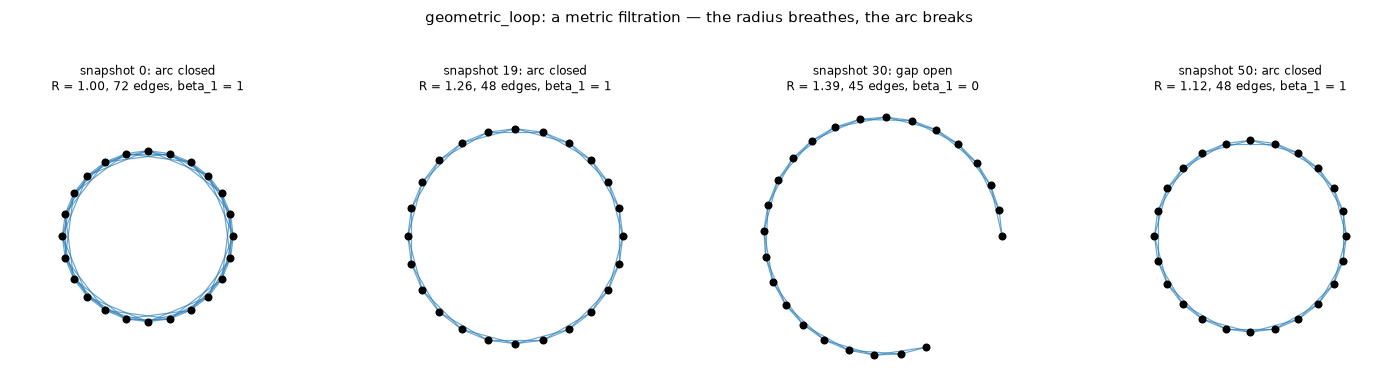

In [18]:
loop = build_dynamic_graph("geometric_loop", CONFIG)
lgt = loop.ground_truth

# The snapshots are stored as DISTANCES, so the point positions are recovered from the schedule.
def loop_points(t):
    gap = loop_cfg.gap_angle if loop_cfg.gap_open_at <= t < loop_cfg.gap_close_at else 2 * np.pi / n
    radius = np.interp(t, np.linspace(0, CONFIG.dynamic_events.n_snapshots - 1,
                                      len(radii)), radii)
    a = np.arange(n) * (2 * np.pi - gap) / (n - 1)
    return np.c_[radius * np.cos(a), radius * np.sin(a)], radius, gap

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.5))
for ax, t in zip(axes, (0, 19, 30, 50)):
    pts, radius, gap = loop_points(t)
    adj = adjacency_from_snapshot(loop.snapshots[t], edge_rule=lgt.edge_rule,
                                  edge_threshold=lgt.edge_threshold)
    iu = np.triu_indices(n, 1)
    for i, j in zip(iu[0][adj[iu] > 0], iu[1][adj[iu] > 0]):
        ax.plot(*pts[[i, j]].T, color="tab:blue", lw=0.8, alpha=0.65, zorder=2)
    ax.scatter(*pts.T, s=18, color="k", zorder=3)
    state = "gap open" if gap > 2 * np.pi / n else "arc closed"
    ax.set_title(f"snapshot {t}: {state}\nR = {radius:.2f}, {int(adj.sum() // 2)} edges, "
                 f"beta_1 = {lgt.betti_curve[1][t]}", fontsize=8)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
fig.suptitle("geometric_loop: a metric filtration — the radius breathes, the arc breaks",
             fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

Both mechanisms are visible at once. The radius changes from frame to frame and **changes
the graph** (the edge count differs between panels), but $\beta$ does not move. The gap in the arc
does move it. This is what makes the dataset a negative control: a detector that fires on a change
of complex will be caught on radius breathing.

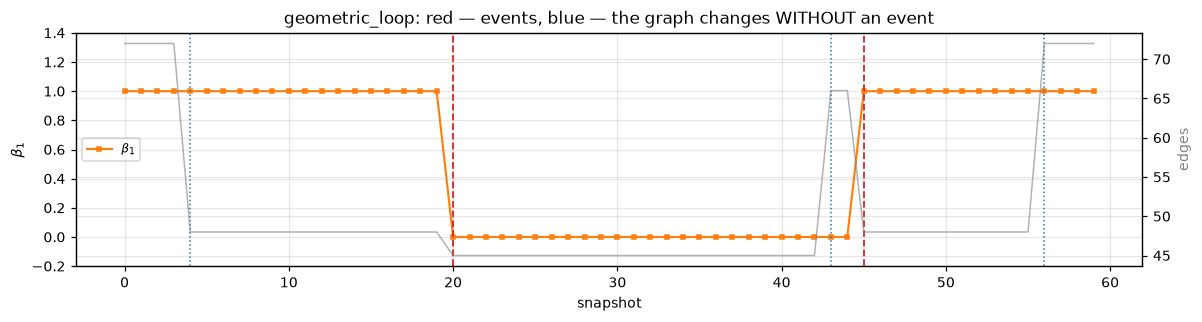

the graph changes at snapshots:  [4, 20, 43, 45, 56]
events are scheduled at:         [20, 45]
radius breathing without event:  [4, 43, 56]
distinct graphs: 4 over 60 snapshots


In [19]:

graphs = [adjacency_from_snapshot(s, edge_rule=lgt.edge_rule, edge_threshold=lgt.edge_threshold)
          for s in loop.snapshots]
changes = [t for t in range(1, len(graphs)) if not np.array_equal(graphs[t], graphs[t - 1])]
scheduled = {e.snapshot for e in lgt.events}

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(lgt.betti_curve[1], "-s", ms=2.5, lw=1.4, label=r"$\beta_1$", color="tab:orange")
ax2 = ax.twinx()
ax2.plot([int(g.sum() // 2) for g in graphs], lw=1, color="gray", alpha=0.6, label="edges")
ax2.set_ylabel("edges", color="gray")
for t in changes:
    is_event = t in scheduled
    ax.axvline(t, color="tab:red" if is_event else "tab:blue", ls="--" if is_event else ":",
               lw=1.2 if is_event else 1)
ax.set_xlabel("snapshot"); ax.set_ylabel(r"$\beta_1$"); ax.set_ylim(-0.2, 1.4)
ax.set_title("geometric_loop: red — events, blue — the graph changes WITHOUT an event")
ax.legend(fontsize=8, loc="center left"); fig.tight_layout(); plt.show()

print(f"the graph changes at snapshots:  {changes}")
print(f"events are scheduled at:         {sorted(scheduled)}")
print(f"radius breathing without event:  {[t for t in changes if t not in scheduled]}")
print(f"distinct graphs: {len({g.tobytes() for g in graphs})} over {len(graphs)} snapshots")

The three snapshots where the graph changes without an event are **the strongest negative
control of the dataset**: a detector that fires on a change of complex will be caught here. The test
names them individually, because a check "over the whole range" would also pass on a dataset where
the complex never changed.

## Oscillators: series → sliding window → dynamic graph

### What this models

Family 3 is a synthetic analogue of fMRI. The real processing chain looks like this: time series are
recorded from brain regions, a sliding window computes correlations between them, a dynamic network
is built from the correlation matrices, and persistence from that. On real data **not one** step of
this chain can be checked: it is unknown what the coupling actually was.

Here the coupling is set by a **schedule**, i.e. known exactly, and the whole chain becomes
checkable.

The series are generated by two classical systems of coupled oscillators:

- **Kuramoto** — phase oscillators,
  $\dot\theta_i = \omega_i + \frac{K}{N}\sum_j A_{ij}(t)\sin(\theta_j - \theta_i)$,
  observable $x_i = \sin\theta_i$. Coupled channels synchronise in phase.
- **Rössler** — chaotic attractors with diffusive coupling. At $c = 5.7$ the system is chaotic,
  giving series noticeably less regular than Kuramoto's.

### What a "coupling regime" is

**A regime is a partition of the channels into blocks.** The coupling matrix of a regime is block
diagonal: $A_{ij} = 1$ if $i$ and $j$ are in the same block, otherwise 0. It is stored as a separate
array `coupling.npy` — one matrix per regime.

Neighbouring partitions must be related by **refinement** — otherwise the word "merge" loses its
meaning. The transition $[15,15] \to [10,10,10]$ is neither a merge nor a split: neither partition
refines the other, the blocks are simply recut. The adopted schedule at 30 channels:

$$[10,10,10] \;\longrightarrow\; [20,10] \;\longrightarrow\; [10,10,10]$$

The first transition is a **merge** (two blocks of 10 become one of 20), the second a **split**
back.

Below: on top the series itself (four channels of thirty, vertical lines are regime boundaries), at
the bottom three coupling matrices, one per regime.

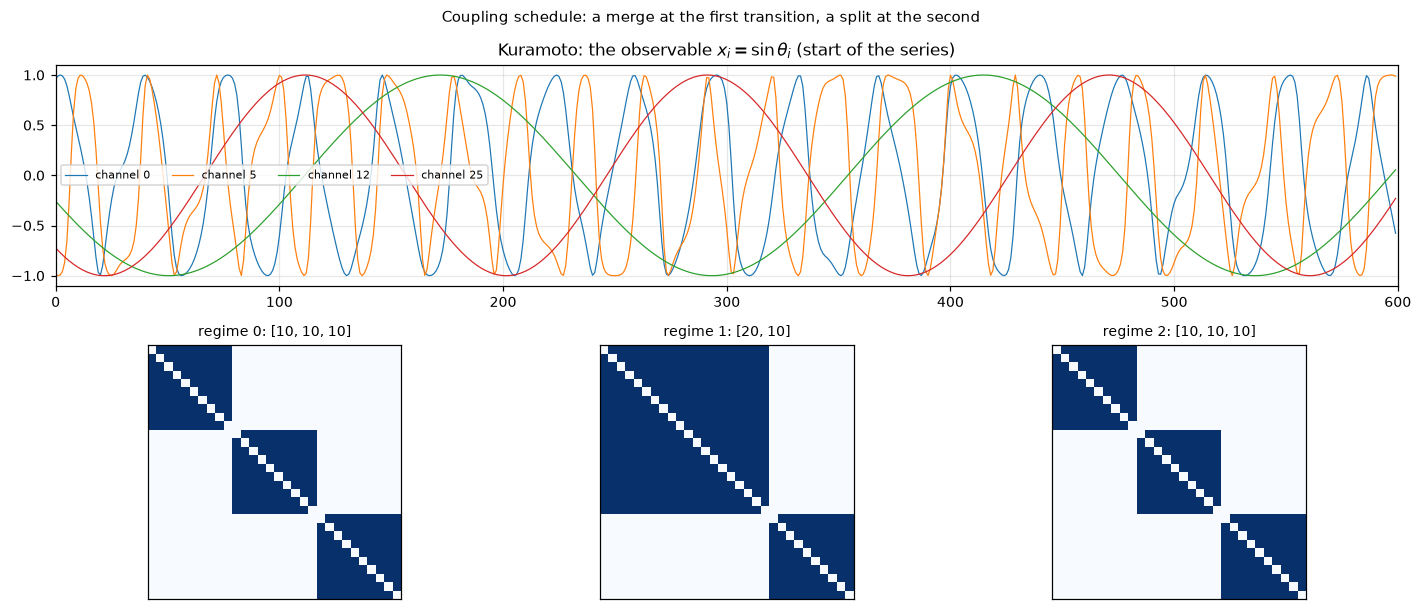

In [20]:
kuramoto = build_series("kuramoto", CONFIG)
osc, win = CONFIG.oscillators, CONFIG.sliding_window
schedule = osc.coupling_schedule

fig = plt.figure(figsize=(13, 5.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])

ax = fig.add_subplot(gs[0, :])
for ch in (0, 5, 12, 25):
    ax.plot(kuramoto.series[ch, :600], lw=0.8, label=f"channel {ch}")
for k in range(1, len(schedule.regimes)):
    ax.axvline(k * schedule.regime_length, color="k", ls="--", lw=1)
ax.set_xlim(0, 600); ax.set_title("Kuramoto: the observable $x_i = \\sin\\theta_i$ (start of the series)")
ax.legend(fontsize=7, ncol=4)

for i, (matrix, partition) in enumerate(zip(kuramoto.coupling, schedule.regimes)):
    ax = fig.add_subplot(gs[1, i])
    ax.imshow(matrix, cmap="Blues"); ax.set_title(f"regime {i}: {list(partition)}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Coupling schedule: a merge at the first transition, a split at the second", fontsize=10)
fig.tight_layout(); plt.show()

### Sliding window: the series back into a network

A window of length $L$ with step $s$; in each window the Pearson correlation matrix between the
channels is computed. The result is a sequence of weighted fully connected graphs, i.e. again a
dynamic graph, but obtained from a series rather than assigned.

Two subtleties, both essential:

**Similarity is $\lvert r\rvert$, not $r$.** Distances are $d = 1 - \lvert r\rvert$. The absolute
value is not cosmetic: $1 - r$ at $r < 0$ exceeds one, while a distance matrix must be
non-negative. In substance, anticorrelation is also a connection, and a strong one in absolute
value.

**The window is bounded on both sides**, not one:

$$\text{oscillation period} \;\ll\; L\,\Delta t \;\ll\; \text{regime duration}$$

From above: a window longer than the interval between regime changes smears the event. From below: a
window shorter than several periods measures not coupling but a common trend — over a fraction of a
period any two smooth sinusoids look alike. The lower bound was added after a measurement: at 0.16
periods per window the within-block (0.946) and between-block (0.936) correlations are
**indistinguishable**.

Below — how well the coupling recovered by the window agrees with the true $A(t)$. The statistic:
the $\lvert r\rvert$ matrix averaged over a regime's windows against that regime's $A$ (per single
window the agreement is too noisy to threshold).

In [21]:
corr = sw.correlation_windows(kuramoto.series, length=win.length, step=win.step)
sim = sw.similarity_from_correlation(corr)
starts = sw.window_starts(osc.n_timepoints, length=win.length, step=win.step)
off = ~np.eye(osc.n_channels, dtype=bool)

grouped = {}
for i, s in enumerate(starts):
    r = sw.regime_of_window(int(s), length=win.length, regime_length=schedule.regime_length,
                            n_regimes=len(schedule.regimes))
    if r is not None:
        grouped.setdefault(r, []).append(sim[i])

print("Agreement of the recovered coupling with the true A(t)")
print(f"(the |r| matrix averaged over a regime's windows against that regime's A)\n")
print(f"{'regime':>7}{'partition':>16}{'agreement':>11}")
print("-" * 34)
for r, mats in sorted(grouped.items()):
    mean = np.mean(mats, axis=0)
    agreement = float(np.corrcoef(mean[off], kuramoto.coupling[r][off])[0, 1])
    print(f"{r:>7}{str(list(schedule.regimes[r])):>16}{agreement:>11.3f}")
print(f"\nthreshold min_coupling_agreement = {win.min_coupling_agreement}")

Agreement of the recovered coupling with the true A(t)
(the |r| matrix averaged over a regime's windows against that regime's A)

 regime       partition  agreement
----------------------------------
      0    [10, 10, 10]      0.395
      1        [20, 10]      0.688
      2    [10, 10, 10]      0.383

threshold min_coupling_agreement = 0.25


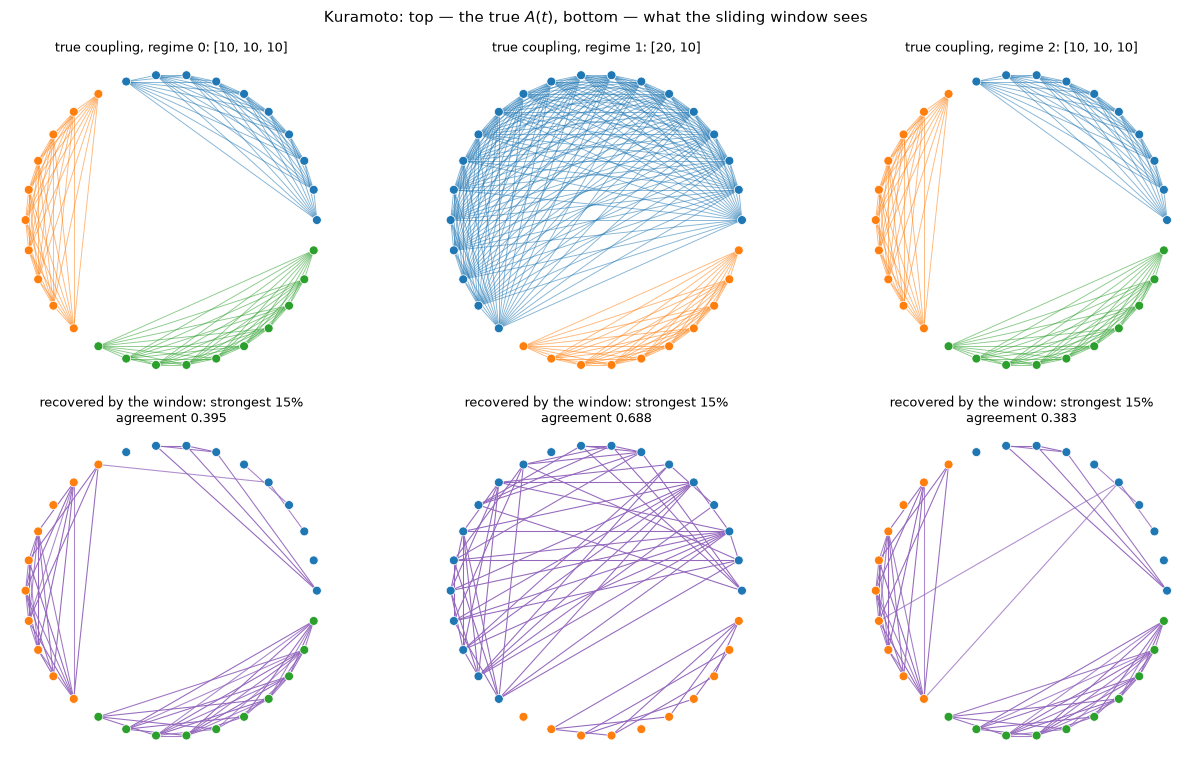

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
osc_ang = np.linspace(0, 2 * np.pi, osc.n_channels, endpoint=False)
osc_pos = np.c_[np.cos(osc_ang), np.sin(osc_ang)]

def block_labels(partition):
    return np.repeat(np.arange(len(partition)), partition)

for col, (regime, mats) in enumerate(sorted(grouped.items())):
    lab = block_labels(schedule.regimes[regime])
    iu = np.triu_indices(osc.n_channels, 1)

    ax = axes[0, col]
    truth = kuramoto.coupling[regime]
    for i, j in zip(iu[0][truth[iu] > 0], iu[1][truth[iu] > 0]):
        ax.plot(*osc_pos[[i, j]].T, color=palette(lab[i]), lw=0.6, alpha=0.55)
    ax.scatter(*osc_pos.T, s=34, c=[palette(k) for k in lab], zorder=3,
               edgecolor="white", lw=0.5)
    ax.set_title(f"true coupling, regime {regime}: {list(schedule.regimes[regime])}",
                 fontsize=8.5)
    ax.set_aspect("equal"); ax.axis("off")

    ax = axes[1, col]
    recovered = np.mean(mats, axis=0)
    keep = recovered[iu] > np.quantile(recovered[iu], 0.85)
    for i, j, w in zip(iu[0][keep], iu[1][keep], recovered[iu][keep]):
        ax.plot(*osc_pos[[i, j]].T, color="tab:purple", lw=0.7, alpha=float(w))
    ax.scatter(*osc_pos.T, s=34, c=[palette(k) for k in lab], zorder=3,
               edgecolor="white", lw=0.5)
    agreement = float(np.corrcoef(recovered[off], truth[off])[0, 1])
    ax.set_title(f"recovered by the window: strongest 15%\nagreement {agreement:.3f}",
                 fontsize=8.5)
    ax.set_aspect("equal"); ax.axis("off")

fig.suptitle("Kuramoto: top — the true $A(t)$, bottom — what the sliding window sees",
             fontsize=10)
fig.tight_layout(); plt.show()

The top row is the input set by the schedule; the bottom row is what can be recovered from
the series. The block structure is recognisable, but not perfectly: coupling within a block of
phase-locked oscillators shows up as $|\cos\Delta\varphi|$, and some pairs within a block look
weaker than some pairs between blocks.

**What this statistic does not do: it does not distinguish regimes.** Agreement with *another*
regime reaches 0.440 against a true minimum of 0.383 — the classes overlap, and no threshold will
separate them. This follows from the nesting of partitions: $[20,10]$ is a coarsening of
$[10,10,10]$, and neighbouring regimes share most of their structure. The honest null control is a
permutation of channel labels: $-0.039\ldots0.068$ against the true $0.383\ldots0.878$.

**The window is bounded on both sides.** From above by the regime duration, from below by the
oscillation period: at 0.16 periods per window the within-block (0.946) and between-block (0.936)
correlations are indistinguishable, and the coupling is not recovered at all.

## Dynamic SBM: a dataset with no topological truth

**The stochastic block model** is the standard way to generate a graph with communities: nodes are
split into blocks, an edge within a block is drawn with probability $p_{in}$, between blocks with a
smaller $p_{out}$. Here the block matrix changes over time: communities merge and split according to
a schedule.

Originally this dataset was meant as a check of $\beta_0$: communities merge → components merge →
$\beta_0$ drops. **A measurement showed that this is wrong.** At $p_{in} = 0.35$, $p_{out} = 0.02$
and blocks of 15 nodes there are 7 to 41 inter-block edges per snapshot: the blocks are stitched
together by dozens of edges, they are never separate components, and merging two communities changes
**nothing** in homology.

That $\beta_0$ does move nonetheless does not help but hinders: the cause is random **isolated
vertices** (a node draws no edge at all with probability $\approx 10^{-3}$; on a $60\times60$
dataset 3.5 such vertices are expected), and its excursions are not tied to the schedule at all.

So the SBM has `truth_kind: partition`: the truth is the community labels and the schedule, fully
known in advance, and `betti_curve` and `events` **are not written**. Recording the measured curve
under the name of truth would declare the pipeline's output to be truth — exactly what all this work
being done before the algorithms is meant to avoid.

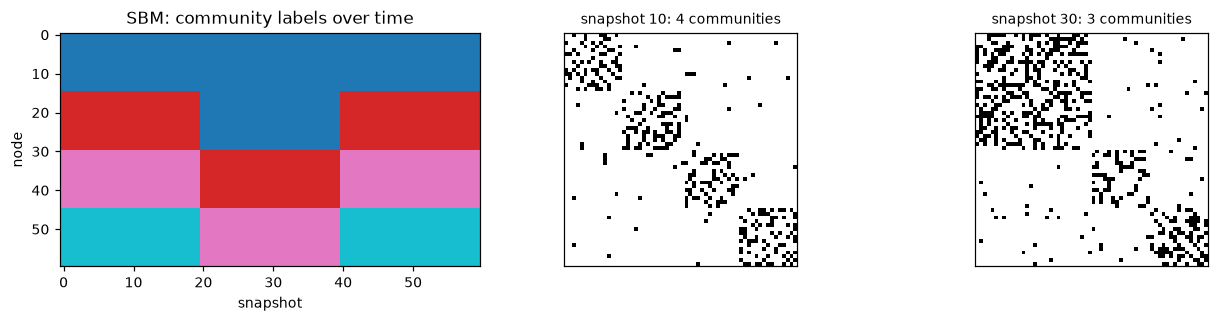

truth_kind = partition, betti_curve = None
components after removing isolated vertices, over all snapshots: [1]


In [23]:
sbm = build_dynamic_sbm(CONFIG)
labels = sbm.ground_truth.community_labels

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].imshow(labels.T, aspect="auto", cmap="tab10", interpolation="nearest")
ax[0].set_xlabel("snapshot"); ax[0].set_ylabel("node"); ax[0].grid(False)
ax[0].set_title("SBM: community labels over time")
for i, t in enumerate((10, 30)):
    ax[i + 1].imshow(sbm.snapshots[t], cmap="Greys", interpolation="nearest")
    ax[i + 1].set_title(f"snapshot {t}: {len(set(labels[t]))} communities", fontsize=9)
    ax[i + 1].set_xticks([]); ax[i + 1].set_yticks([]); ax[i + 1].grid(False)
fig.tight_layout(); plt.show()

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
comps = set()
for s in sbm.snapshots:
    a = s > 0.5; keep = a.sum(1) > 0
    comps.add(connected_components(csr_matrix(a[np.ix_(keep, keep)]), directed=False)[0])
print(f"truth_kind = {sbm.ground_truth.truth_kind}, betti_curve = {sbm.ground_truth.betti_curve}")
print(f"components after removing isolated vertices, over all snapshots: {sorted(comps)}")

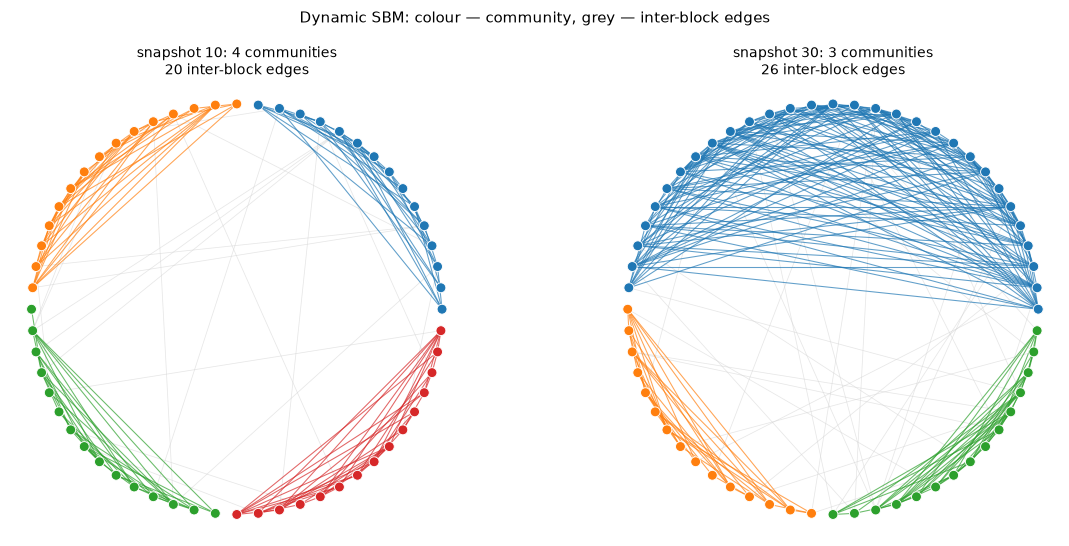

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sbm_ang = np.linspace(0, 2 * np.pi, CONFIG.dynamic_sbm.n_nodes, endpoint=False)
sbm_pos = np.c_[np.cos(sbm_ang), np.sin(sbm_ang)]

for ax, t in zip(axes, (10, 30)):
    lab = labels[t]
    adj = sbm.snapshots[t] > 0.5
    iu = np.triu_indices(len(lab), 1)
    for i, j in zip(iu[0][adj[iu]], iu[1][adj[iu]]):
        same = lab[i] == lab[j]
        ax.plot(*sbm_pos[[i, j]].T, lw=0.7 if same else 0.5,
                color=palette(lab[i]) if same else "lightgray",
                alpha=0.7 if same else 0.55, zorder=1 if same else 0)
    ax.scatter(*sbm_pos.T, s=42, c=[palette(k) for k in lab], zorder=3,
               edgecolor="white", lw=0.6)
    cross = int(adj[iu][lab[iu[0]] != lab[iu[1]]].sum())
    ax.set_title(f"snapshot {t}: {len(set(lab))} communities\n"
                 f"{cross} inter-block edges", fontsize=9)
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("Dynamic SBM: colour — community, grey — inter-block edges", fontsize=10)
fig.tight_layout(); plt.show()

**A community merge is not a homological event.** The blocks are stitched together by dozens
of edges (grey lines in the figure), the graph is connected, and the merge changes nothing in
homology. $\beta_0$ does wander between 1 and 2 — but because of random isolated vertices, not
communities.

So the SBM has `truth_kind: partition`, and `betti_curve` and `events` **are not written**: a
measured curve under the name of truth would be truth as pipeline output.

---
# S8. Noise and null models

Family 4 answers two questions the previous families did not touch: **how answers degrade under
controlled noise** and **whether the pipeline fires where there is no structure at all**.

Four noise mechanisms, each with its level as a parameter:

| Mechanism | What it corrupts | Level |
|---|---|---|
| `point_jitter` | point positions in a cloud | $\sigma$ of a Gaussian shift |
| `weight_jitter` | network edge weights | $\sigma$ |
| `spurious_edges` | adds false edges | $p^+$ — a fraction of the **absent** ones |
| `missing_edges` | removes existing ones | $p^-$ — a fraction of the existing ones |

**Null models** are data without topological structure: a uniform cloud in a cube (for the "cloud →
Rips" pipeline) and an Erdős–Rényi graph $G(n,p)$ (for the "snapshots → flag complex" pipeline).

## Stability: the bound $d_B \le 2\,d_H$, not $d_H$

### What stability of diagrams is

The key property of persistent homology, for which it is applied to noisy data at all: **a small
perturbation of the data gives a small perturbation of the diagram**. This is the
Cohen-Steiner–Edelsbrunner–Harer theorem, and it is stated through two measures:

- $d_H$ — the **Hausdorff distance** between point clouds: how far the points had to be moved;
- $d_B$ — the **bottleneck distance** between diagrams: the minimum over all matchings of bars of
  the maximum shift of a single bar.

### The factor two that was missing from the document at first

The original edition of the project said $d_B \le d_H$. This is **wrong**. The right form is:

$$d_B \le 2\,d_{GH} \le 2\,d_H$$

The two is not fitted to the measurement; it follows from the parametrisation. The filtration value
of a simplex in the Rips complex is its **diameter**, not its radius. If each point is moved by at
most $\delta$, then for the pair realising the maximum **both ends** move, so the diameter changes
by $2\delta$. The form without the two would correspond to a filtration parametrised by radius
(the Čech complex), not by diameter.

Checked by measurement on the circle (400 points, three calibration seeds, four jitter levels —
twelve combinations): **nine of twelve** violate $d_B \le d_H$, the ratio reaches 1.33, and none
violates the $2\,d_H$ bound. The figure is below; the cell computes exactly these conditions, so its
output is the source of the numbers quoted.

A trap in writing the test: in $H_0$ the bound $d_B \le d_H$ is violated **nowhere** —
zero-dimensional bars are all born at zero, and bottleneck behaves more gently on them. A test
written on $H_0$ alone would pass and leave a wrong theorem in the document.

But first — what noise looks like at all.

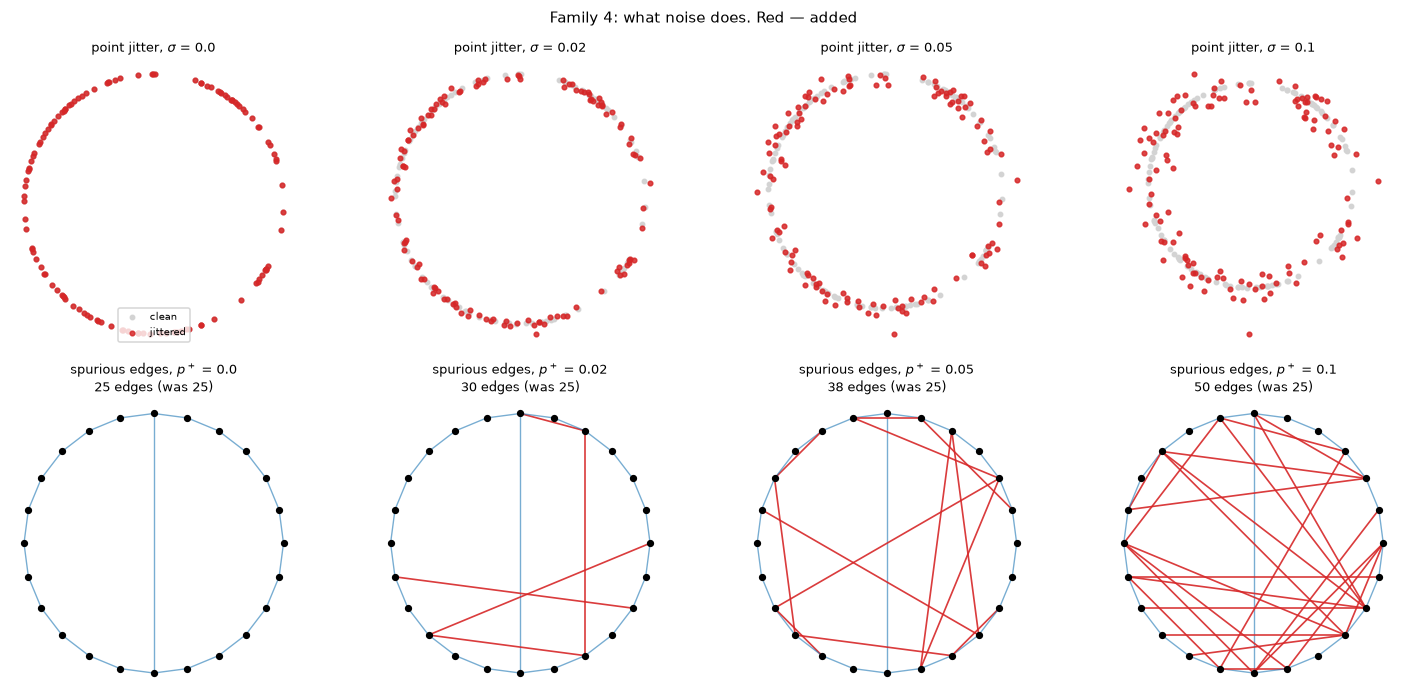

In [25]:
from tdadyn.synthetic import make_noisy_snapshots

fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.4))
clean_ring = build_static_cloud("circle", CONFIG, n_points=120, noise_sigma=0.0).points
for ax, lvl in zip(axes[0], CONFIG.noise.point_jitter_sigma):
    pts = make_jittered_cloud(clean_ring, "b", lvl, 0, rng_for(CONFIG.seed, "nb_show")).points
    ax.scatter(*clean_ring.T, s=8, color="lightgray", label="clean")
    ax.scatter(*pts.T, s=9, color="tab:red", alpha=0.85, label="jittered")
    ax.set_title(f"point jitter, $\\sigma$ = {lvl}", fontsize=8.5)
    ax.set_aspect("equal"); ax.axis("off")
axes[0, 0].legend(fontsize=6.5, loc="lower center")

base_graph = lifecycle.snapshots
for ax, lvl in zip(axes[1], CONFIG.noise.spurious_edge_fraction):
    noisy = make_noisy_snapshots(base_graph, "b", "spurious_edges", lvl, gt.edge_rule,
                                 gt.edge_threshold, 0, rng_for(CONFIG.seed, "nb_sp"))
    adj = adjacency_from_snapshot(noisy.snapshots[30], edge_rule=gt.edge_rule,
                                  edge_threshold=gt.edge_threshold)
    orig = adjacency_from_snapshot(base_graph[30], edge_rule=gt.edge_rule,
                                   edge_threshold=gt.edge_threshold)
    iu = np.triu_indices(n_nodes, 1)
    for i, j in zip(iu[0][adj[iu] > 0], iu[1][adj[iu] > 0]):
        added = orig[i, j] == 0
        ax.plot(*ring_pos[[i, j]].T, color="tab:red" if added else "tab:blue",
                lw=1.1 if added else 0.9, alpha=0.9 if added else 0.6, zorder=2)
    ax.scatter(*ring_pos.T, s=14, color="k", zorder=3)
    ax.set_title(f"spurious edges, $p^+$ = {lvl}\n{int(adj.sum() // 2)} edges "
                 f"(was {int(orig.sum() // 2)})", fontsize=8.5)
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("Family 4: what noise does. Red — added", fontsize=10)
fig.tight_layout(); plt.show()

$p^+$ is a fraction of the **absent** edges, not of the existing ones, so at $p^+ = 0.10$ on
a sparse graph noticeably more edges are added than there were. Level 0.0 gives the source dataset
bitwise, and this is checked by comparing sha256 in the manifest.

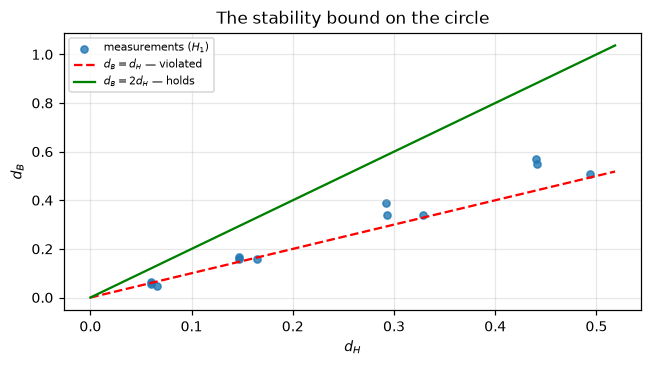

violations of d_B <= d_H:    9 of 12, ratio up to 1.33
violations of d_B <= 2*d_H:  0 of 12


In [26]:
from persim import bottleneck

def dgm1(points):
    d = pairwise_distances(points)
    dg = persistence_diagrams(d, max_homology_dim=1, coeff_field=TOPOLOGY.coeff_field)[1]
    return dg[np.isfinite(dg[:, 1])]

def hausdorff(a, b):
    d = np.linalg.norm(a[:, None] - b[None, :], axis=-1)
    return max(d.min(1).max(), d.min(0).max())

# The conditions are those of method.md 4.1 and of the test: 400 points, the "stability" stream.
# Otherwise prose and output diverge: a measurement on another stream gives a different count.
base = build_static_cloud("circle", CONFIG, n_points=400, noise_sigma=0.0)
clean = dgm1(base.points)
levels = [0.02, 0.05, 0.10, 0.15]
rows = []
for lvl in levels:
    for seed in TOPOLOGY.calibration_seeds:
        pts = make_jittered_cloud(base.points, "base", lvl, 0, rng_for(seed, "stability")).points
        rows.append((lvl, bottleneck(clean, dgm1(pts)), hausdorff(base.points, pts)))

fig, ax = plt.subplots(figsize=(6, 3.4))
db = np.array([r[1] for r in rows]); dh = np.array([r[2] for r in rows])
ax.scatter(dh, db, s=22, alpha=0.8, label=r"measurements ($H_1$)")
line = np.linspace(0, dh.max() * 1.05, 10)
ax.plot(line, line, "r--", label=r"$d_B = d_H$ — violated")
ax.plot(line, 2 * line, "g-", label=r"$d_B = 2 d_H$ — holds")
ax.set_xlabel(r"$d_H$"); ax.set_ylabel(r"$d_B$"); ax.legend(fontsize=7)
ax.set_title("The stability bound on the circle")
fig.tight_layout(); plt.show()

print(f"violations of d_B <= d_H:    {(db > dh).sum()} of {len(rows)}, ratio up to {(db/dh).max():.2f}")
print(f"violations of d_B <= 2*d_H:  {(db > 2*dh).sum()} of {len(rows)}")

**Trap:** in $H_0$ the bound $d_B \le d_H$ is violated nowhere — a test written on
zero-dimensional bars alone would pass and leave a wrong theorem in the document.

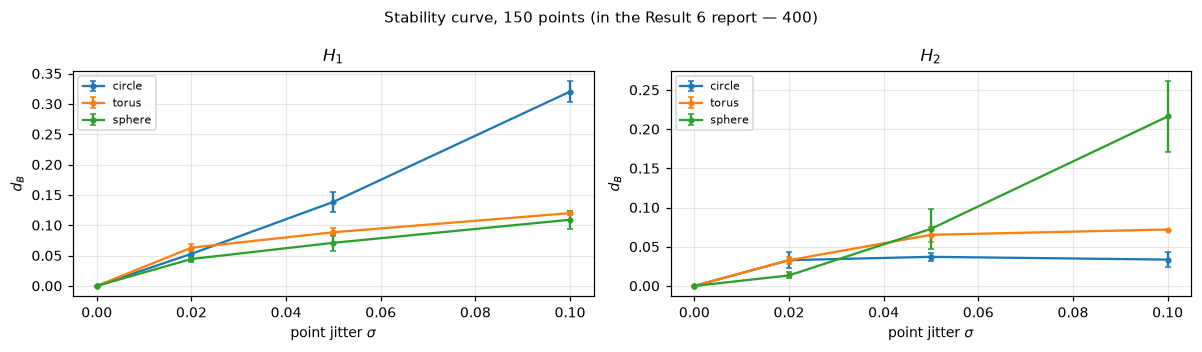

In [27]:
from tdadyn.synthetic.build import STABILITY_OBJECTS, stability_curve
import dataclasses

reduced = dataclasses.replace(
    CONFIG,
    static_clouds=dataclasses.replace(CONFIG.static_clouds, n_points=150),
    noise=dataclasses.replace(CONFIG.noise, n_repeats=3))
curve = stability_curve(reduced)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for dim, ax in zip(("H1", "H2"), axes):
    for name in STABILITY_OBJECTS:
        e = curve["objects"][name]
        ax.errorbar(e["levels"], e[dim]["mean"], yerr=e[dim]["spread"], marker="o", ms=3,
                    capsize=2, label=name)
    ax.set_xlabel(r"point jitter $\sigma$"); ax.set_ylabel(r"$d_B$")
    ax.set_title(f"${dim[0]}_{dim[1]}$"); ax.legend(fontsize=7)
fig.suptitle(f"Stability curve, {curve['n_points']} points "
             f"(in the Result 6 report — {CONFIG.static_clouds.n_points})", fontsize=10)
fig.tight_layout(); plt.show()

This is **Result 6** of the project: $d_B$ as a function of the noise level. It is shown here
on a reduced number of points for the sake of computation time; the reported artefact is produced by
the build with the `--results` flag at the working size.

**One circle is not enough.** Each object is informative exactly in its own dimension and flat in
the other: the circle's $H_2$ is flat (no cavity — nothing to move), the sphere's $H_1$ barely moves
(no loops). A curve on one object is informative by half — and $H_2$ is the most fragile part of the
pipeline, exactly the one the old significance criterion used to lose.

## Null models measure the false positive rate rather than claiming zero

In the original edition the requirement on the null models read: "the null model has no significant
long-lived bars". It is **impossible to satisfy**, and this too was established by measurement, not
by argument.

A random graph honestly has cycles. This is not an artefact of computation and not noise that can
be cut off by a threshold — it is the **null distribution** against which everything else is
measured. The table below: Betti numbers of an Erdős–Rényi graph on 24 nodes at growing density,
computed by the reference implementation, five realisations per density.

The **spread** over realisations is given, not one "typical" value: a null model has no typical
value, and the first edition of this table, which kept the first realisation of five, flipped with a
change of random stream.

In [28]:
pairs = 24 * 23 // 2
print(f"ER on n=24, flag complex by the reference, 5 realisations per density")
print(f"(density of cycle_lifecycle: 24/{pairs} = {24/pairs:.3f})\n")
# The spread over five realisations, not one of them: the "typical" value of a null model
# flips with a change of stream (method.md 4.2).
def span(values):
    lo, hi = min(values), max(values)
    return str(lo) if lo == hi else f"{lo}-{hi}"

print(f"{'m':>5}{'p':>8}{'beta_0':>9}{'beta_1':>9}{'beta_2':>9}   clean (1,0,0)")
print("-" * 62)
for m in (12, 24, 36, 60, 100, 180, 220):
    out, clean_n = [], 0
    for rep in range(5):
        r = rng_for(CONFIG.seed, "er_density", rep)
        iu = np.triu_indices(24, 1)
        pick = r.choice(len(iu[0]), size=m, replace=False)
        a = np.zeros((24, 24)); a[iu[0][pick], iu[1][pick]] = 1.0; a = a + a.T
        b = reference.betti_numbers_of_graph(a, max_homology_dim=2, max_nodes=30)
        bb = (b[0], b[1], b[2]); out.append(bb); clean_n += bb == (1, 0, 0)
    spans = [span([o[k] for o in out]) for k in range(3)]
    print(f"{m:>5}{m/pairs:>8.3f}{spans[0]:>9}{spans[1]:>9}{spans[2]:>9}   {clean_n}/5")

ER on n=24, flag complex by the reference, 5 realisations per density
(density of cycle_lifecycle: 24/276 = 0.087)

    m       p   beta_0   beta_1   beta_2   clean (1,0,0)
--------------------------------------------------------------
   12   0.043    12-14      0-1        0   0/5
   24   0.087      4-5      2-5        0   0/5
   36   0.130      1-3     8-12        0   0/5
   60   0.217        1    13-22        0   0/5
  100   0.362        1      3-7      3-6   0/5


  180   0.652        1        0      0-2   3/5
  220   0.797        1        0        0   5/5


It becomes reliably clean only at $p \gtrsim 0.8$ — on an almost complete graph, which as a
null model controls nothing. At $p = 0.652$ three realisations of five are already clean, but the
other two keep $\beta_2 = 2$: the regime has not yet left the region where features appear by
themselves. So the truth of the null dataset is: **there is no schedule, the event list is empty**.
This is a statement about the construction, checkable at the generator level.

**The criterion itself has a non-zero false positive rate**, and it does not shrink to zero with
sample size. Measured on the generator's stream, 200 trials, $\mathbb{R}^3$:

| $n$ | Misses | Rate | 95% upper |
|---|---|---|---|
| 200 | 12/200 | 6.0% | 10.2% |
| 400 | 3/200 | **1.5%** | 4.3% |

*The table is a quotation from `docs/method.md` §1.2a: 200 trials are too slow to compute in a report
cell.*

The mechanism: when exactly **one** bar survives above the noise floor, there is nothing to compare
it with, and the lone survivor is significant by construction. The threshold in the config is set
above the 95% bound of the true rate, not above the zero observed on the calibration seeds: sixty
trials do not establish zero.

---
# S9. Build and reproducibility

One command builds all 38 datasets in a few seconds:

```
python -m tdadyn.synthetic.build --config config.yaml
```

Next to the data a **`manifest.json`** is written — a registry of everything built: dataset
identifier, family, generator, seed, path, parameters, package version, date and hashes. It serves
two purposes: reproducibility and quick detection that data were rebuilt with different parameters.

Two decisions about hashes that look technical and are not:

**sha256 is computed over the bytes of the `.npy` file**, not over `ndarray.tobytes()`. The result
can be checked with a plain `shasum -a 256`, and the header goes into the hash — so a changed dtype
or shape cannot hide behind an identical payload.

**Not only the array is hashed but also the truth** — the `truth_sha256` field. Without it the check
"a rebuild gives the same hashes" would not cover the expected Betti numbers, the event log and the
notes: arrays do not change when the truth is edited, and a substitution would go unnoticed. It is
computed over a canonical serialisation of **the parsed record**, not over the bytes of the JSON: a
byte hash would absorb indentation and key order, and cosmetic reformatting would read as a change of
data.

In [29]:
e = next(x for x in ENTRIES if x.generator == "cycle_lifecycle")
print("A manifest entry:\n")
for field in ("dataset_id", "family", "generator", "seed", "path"):
    print(f"  {field:<16}{getattr(e, field)}")
print(f"  {'arrays':<16}{ {k: v[:16] + '...' for k, v in e.arrays.items()} }")
print(f"  {'truth_sha256':<16}{e.truth_sha256[:16]}...")
print(f"\nDropped when comparing a rebuild: generated_at, package_version")
print("truth_sha256 is NOT dropped: it is reproducible and therefore takes part in the comparison.")
print("\nWithout it the 'same hashes' check would not cover the expected Betti numbers,")
print("the event log and notes: arrays do not change when the truth is edited.")

A manifest entry:

  dataset_id      cycle_lifecycle_N24_T60_w1_thr0.5_sched12-27-41-48-55_seed20260201
  family          dynamic_graph
  generator       cycle_lifecycle
  seed            20260201
  path            dynamic_graph/cycle_lifecycle_N24_T60_w1_thr0.5_sched12-27-41-48-55_seed20260201
  arrays          {'snapshots.npy': '0d25d71fa73eed39...'}
  truth_sha256    c1b5541bba25137b...

Dropped when comparing a rebuild: generated_at, package_version
truth_sha256 is NOT dropped: it is reproducible and therefore takes part in the comparison.

Without it the 'same hashes' check would not cover the expected Betti numbers,
the event log and notes: arrays do not change when the truth is edited.


**The zero-level check is free and catches a whole class of failures.** The sha256 of the
perturbed array at level 0.0 equals the sha256 of the base; both numbers are already in the manifest.
It catches a wrongly connected base, a shift of the random stream between levels and an
unconditionally applied `clip`.

**A caveat on reproducibility.** The wording is "two builds **in one environment** give the same
entries". More cannot be promised: Rössler at $c = 5.7$ is chaotic, and a change of scipy version,
method or tolerances moves the series entirely.

---
# Decisions at the forks

Places where the specification allowed several readings and one had to be chosen. They are gathered
in one table because they all share a common property: **a wrong choice would not have caused a
crash**. It would have given a plausible dataset with wrong truth — an error that would have shown up
not here but in Task 2, where the algorithm would have been validated against a corrupted reference,
and would have been discovered at best in peer review.

So every choice here is justified not by an argument but by a measurement or a proof, and that is
what the "why" column contains.

| Fork | Decision | Why |
|---|---|---|
| Significance criterion | a gap in the spectrum with a step into the dust | the old rule: 9 misses out of 54, errs in both directions |
| Pairing of the $H_1$ death | paired with the birth when the path closed | the decomposition of a zigzag module is unique; not a convention |
| Closed state of the arc | $\delta = 2\pi/n$, not zero | at zero two points coincide, and $\beta$ does not see it |
| Kind of truth vs layout | a separate field `truth_kind` | SBM: a graph on disk, a partition as truth |
| Threshold direction | the `edge_rule` field in the truth | otherwise the metric dataset is read as the complement |
| SBM truth | a partition; no curve written | a measured curve = truth as pipeline output |
| Null model truth | an empty event log | $(1,0,0)$ is unreachable at any working density |
| Family 4 layout | only the perturbed array | a "source + derived" pair is inconsistent in both directions |
| Coupling agreement threshold | calibrated on 3 seeds, null control is label permutation | another regime is not a null control: the partitions are nested |
| Stability bound | $d_B \le 2 d_H$ | parametrisation by diameter; 9 of 12 violate the form without the two |

---

# Limitations

**What these data do not do:**

- **They do not replace real data.** The dynamics make no claim to realism; the oscillator series are
  an fMRI analogue in coupling structure, not in spectrum or noise level.
- **They do not confirm the scientific meaningfulness** of a dataset for a particular task. The
  tests check conformance to the declared truth, and only that.
- **They give no universal thresholds.** The criterion parameters were calibrated on family-1 clouds
  in $\mathbb{R}^3$ and $\mathbb{R}^4$. They do not transfer to the connectomes of Task 3: there the
  distance distribution differs and, above all, there is no known $\beta_k$ to calibrate against.
- **The criterion is not invariant under reparametrisation of the filtration.** A monotone
  similarity → distance transform preserves the structure of the diagram but distorts the
  persistences, and the criterion compares exactly those.
- **Null models do not claim the absence of features** — they allow the false positive rate to be
  measured.
- **Rössler reproducibility holds within one environment.**
- **Wasserstein is not computed**: there is one measure of diagram discrepancy — bottleneck.

**Known artefacts that are not bugs:** the Rips complex of a circle as the scale grows is
successively equivalent to $S^1, S^3, S^5,\dots$; Betti numbers from a noisy sample are recovered
only as persistent ones; $H_0$ always contains one infinite bar.

---

# What next

| | |
|---|---|
| **Task 2** | zigzag algorithms and event localisation — `docs/handoff.md` lists the traps |
| **Task 3** | persistent invariants of connectomes; the criterion parameters are not inherited there |
| **Result 6** | stability and complexity; the curve is produced by the build with `--results` |